# E118 · Did ideology move candidates off their polls? Opponents, party money and labels given after the fact

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: US House and Senate races of 2018, 2022 and 2026. Polls, certified results, partisan lean, candidate receipts and historical poll errors come from E94's files (**FEC**, public domain; **FiveThirtyEight**, CC BY 4.0; **Wikipedia** as of 2026-11-02, CC BY-SA 4.0). New here, built by `tools/build_e118_data.py`: caucus rosters and endorsement lists from **Wikipedia** revisions and **Internet Archive** captures dated before each election; first-dimension DW-NOMINATE from **Voteview** (Lewis, Poole, Rosenthal, Boche, Rudkin and Sonnet), as captured before the election and as it stands today; independent expenditures by spender and party committees' direct spending from **FEC** bulk files; and **uncertified, incomplete** 2026 vote counts from Wikipedia as of 2026-11-11. Eight derived files, 1.6 MB |
| **You will learn** | Testing a claim that could come out either way, with the outcome, the covariates and the groups **fixed before** any coefficient is seen · **poll error** as an outcome whose noise shrinks with the number of polls, with a **shared error per cycle** and a **sponsor effect** · three variances the data cannot separate, sampled as a **total and its shares** (failure 1), and **Student-t tails** (failure 2) · adjusting for **opponents** and **party money**, and what conditioning on money that follows close races does and does not license · a **multiverse** of group definitions from one compiled model and `with_data` · how **labels given after the result** manufacture an effect, in real data and in simulated elections where ideology does nothing · a **provisional** section on incomplete counts, and the code that reruns it on certified results |

## The question

Within days of an election a familiar reading appears: moderate Democrats beat their polls, candidates
further to the left fell short of theirs, and ideology is the reason. The claim is about **poll error**,
the gap between a result and the final polls, and that is a narrower thing than winning votes. There is
good evidence that ideologically extreme nominees win fewer votes (Canes-Wrone, Brady and Cogan 2002; Hall
2015). But a penalty that voters apply is a penalty that pollsters can measure: if a nominee is too far
from a district, the polls should already say so. For ideology to move a candidate *off* the polls,
something about that candidate's support has to stay invisible to pollsters until the votes are counted.

Three other things can produce the same pattern. The first is the **opponent**. A poll error belongs to a
race, not to one candidate, and a nominee facing a sitting member is in a different kind of race from one
facing a first-time candidate. The second is **party support**. The national committees and their allied
super PACs put money and programmes into some races and not others, and they do not choose at random. The
third is the **label** itself. "Moderate" and "progressive" are often attached to a candidate after the
result is known, by people who have seen which candidates beat their polls. A comparison between groups
that were formed after seeing the outcome can show an effect where there is none: the garden of forking
paths (Gelman and Loken 2013), or hypothesising after the results are known (Kerr 1998).

Poll errors themselves are well studied. Across countries and decades the average error of late polls is a
few points and has not grown (Jennings and Wlezien 2018), and it is about twice what sampling alone would
give, because polls of one election share errors that averaging does not remove (Shirani-Mehr, Rothschild,
Goel and Gelman 2018). Any test of the claim has to carry that shared error, since a year in which every
Democrat beats the polls is a year in which the moderates do too.

This notebook joins the midterms series (E94, E95) and uses its data. It tests the claim on 2018 and 2022,
where polls and certified results both exist, and then looks at what little can be said about 2026. The
test is set up so that it can come out for the claim or against it. The outcome, the rule for the poll
average, the covariates and the lists that define the groups were written into the source before any
ideology coefficient was computed. Three things changed afterwards, none of them by looking at such a
coefficient: the widths of some priors (section 4.1), the way the variances are parameterised (4.2) and
the tails of the likelihood (4.3). Section 6 then refits the model under every alternative we could
defend, so the reader can see what each choice is worth.

| part | question | tool |
|---|---|---|
| 1 | What is the outcome, and what counts as a poll? | a 21-day poll average, sponsor marks, 184 races |
| 2 | Who is "left" and who is "centre", as known before the election? | dated rosters and endorsement lists |
| 3 | What does the commentator's comparison show? | a difference in means with a bootstrap interval |
| 4 | What should a model of poll error contain? | shared error per cycle, sponsor lean, noise by number of polls; a prior predictive check; variance shares (failure 1); Student-t tails (failure 2) |
| 5 | Do opponents and party support change the answer? | covariates added in blocks, pooled money coefficients |
| 6 | Does the answer depend on how the buckets are drawn? | a multiverse of 25 specifications |
| 7 | What can labels given after the result manufacture? | Voteview scores before and after, relabelling, simulated elections with no effect |
| 8 | 2026, provisional | predictions from the 2018 and 2022 model against uncertified counts |
| 9 | Scoring 2026, later | the same section rerun on certified results |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import json
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr
from matplotlib.lines import Line2D
from scipy import stats

from pymc_challenges import data

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests it, which would import all of
# JAX for nothing (see E89). Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 118
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})   # several panels per row
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
T_START = time.time()
TIMES = {}

INK, MUTED, LIGHT = "#222222", "#8a8a8a", "#d9d9d9"
LEFT_C, CEN_C, D_C, R_C = "#7b3294", "#e08e0b", "#2166ac", "#c0392b"
EVE = {2018: "2018-11-05", 2022: "2022-11-07", 2026: "2026-11-02"}    # last day of information
ELEC = {2018: "2018-11-06", 2022: "2022-11-08", 2026: "2026-11-03"}
WINDOW = 21                                                           # days before election day
MIN_BUCKET = 3                                                        # fewer nominees than this are counted, not averaged

## 1 · The data and the outcome

Polls, results, partisan lean and candidate receipts are E94's files, cut at the eve of each election: **5
November 2018, 7 November 2022 and 2 November 2026**. The new files hold what E94 lacked. For every
nominee, `e118_ideology` records membership of caucus rosters and endorsement lists, each read from a
version of its source that existed before that cycle's election day, and `e118_ideology_flags` keeps the
source line behind every entry. `e118_party_ie` splits E94's independent expenditures by spender and by
whether an item supports a candidate or opposes one, and `e118_party_direct` adds what the party
committees spent directly. The two 2026 files hold uncertified counts and are used only in section 8.

In [2]:
NAMES = ("e94_races", "e94_polls", "e94_pollerr", "e118_ideology", "e118_ideology_flags", "e118_party_ie",
         "e118_party_direct", "e118_results_2026", "e118_results_2026_margins", "e118_sources", "e118_build_log")
for name in NAMES:
    data.describe(name)
    print()

e94_races: One row per race: cycle (2016-2026), office (H/S), state, race (e.g. PA-07, OH-S, MN-S2 for a special), region (Census), special, seat (counts toward the next Congress), lean (D-minus-R points on the margin scale: 538 lean for 2016-2022, 2 x Cook PVI for 2026; blank where the lines differ), pvi (2026), inc_party (D, R or blank for an open seat), open, d_inc, r_inc, d_id/r_id (FEC candidate IDs) and names of the top D-side and R candidates, d_is_ind (independent on the D side), contested (both sides on the ballot), split (jungle-style ballot), dem2 (D share of the two-party vote; blank for 2026), winner, rcv (ranked-choice final round used), d_votes, r_votes, *_rec_eve / *_disb_eve / *_coh_eve (receipts, disbursements, cash on hand in reports the FEC had received by the eve: 2018-11-05, 2022-11-07, 2026-11-02), *_rec_final / *_disb_final (cycle totals from weball), member and status (2026), multi_cands (2026: several candidates of one side on the November ballot, as in Louisi

In [3]:
races = data.load("e94_races")
polls = data.load("e94_polls")
pollerr = data.load("e94_pollerr")
ideo = data.load("e118_ideology")
flags = data.load("e118_ideology_flags")
party_ie = data.load("e118_party_ie")
party_direct = data.load("e118_party_direct")
counts26 = data.load("e118_results_2026")
margins26 = data.load("e118_results_2026_margins")
sources = data.load("e118_sources")
build_log = json.load(open(data.path("e118_build_log")))

race_polls = polls[polls.kind.isin(["house", "senate"])].copy()
polled = set(zip(race_polls.cycle, race_polls.race))
wrong_id = [" ".join(v.split()[:3]) for v in build_log["checks"]["e94_fec_ids_that_belong_to_someone_else"]]
print("rows of e94_races whose FEC ID belongs to another member (cycle, race, side):", wrong_id)
print("  2022 FL-26 has a race poll:", (2022, "FL-26") in polled)
nc = ideo[(ideo.cycle == 2026) & (ideo.race == "NC-11") & (ideo.side == "R")].iloc[0]
print(f"2026 NC-11, Republican nominee: incumbent in e94_races {bool(nc.incumbent)}, "
      f"in office on the eve {bool(nc.in_office_on_eve)}, served before {bool(nc.served_before)}")

rows of e94_races whose FEC ID belongs to another member (cycle, race, side): ['2022 FL-26 R']
  2022 FL-26 has a race poll: False
2026 NC-11, Republican nominee: incumbent in e94_races True, in office on the eve False, served before False


Two known defects of `e94_races` are handled here and left alone in E94's files. The 2022 FL-26 row
carries another member's FEC ID for the Republican nominee; that race has no poll, so it never enters. The
2026 NC-11 row marks the Republican nominee as the incumbent, while the legislators' file shows a nominee
who was not in office on the eve and had not served before, so incumbency below is taken from
`in_office_on_eve`.

### The poll average

The outcome needs a rule for "the final polls", fixed once.

**What counts as a poll.** A row of `e94_polls` for a House or Senate race in which both nominees are
named. For 2018 and 2022 these are FiveThirtyEight's records, kept only if they had been entered by the
eve. For 2026 they come from the poll tables of Wikipedia's race articles at their last revision before
the eve; those carry no entry date, so they are cut by the end of fieldwork alone. Where a pollster
reports one poll for several populations we keep the likely-voter version, which matters only in 2026.

**The window.** A final poll is one whose fieldwork ended in the last 21 days before election day. This is
the window FiveThirtyEight's pollster ratings use, and `e94_pollerr` uses it for every race since 1998,
which lets that history serve as a prior. It has a cost: of the 177 and 132 races with any poll in 2018
and 2022, 122 and 63 have one in the window. A race polled only in the summer has no final poll average,
and the gap between a June poll and the result is mostly the campaign. Windows of 42 and 70 days return in
section 6.

**The average.** The plain mean of the polls' two-party margins. Most races have one to three polls, and
weights by sample size or recency would add choices and little else.

**Sponsored polls.** `e94_polls` marks polls paid for by a campaign, a party or a partisan group
(`partisan`, D or R), and FiveThirtyEight's `internal` flag marks a subset of them. They are a large share
of district polling, and they lean towards their sponsor, which alone would move this outcome. Dropping
them would drop the races that have nothing else, so we keep them and carry for each race its **sponsor
share**: the share of its polls with a Democratic sponsor minus the share with a Republican one. The model
estimates the lean, and section 6 repeats the analysis on unsponsored polls only.

In [4]:
P = race_polls.copy()
P["end"] = pd.to_datetime(P.end)
P["days"] = (P.cycle.map(lambda c: pd.Timestamp(ELEC[c])) - P.end).dt.days
P["two"] = 100 * (2 * P.dem / (P.dem + P.rep) - 1)                 # two-party margin, D minus R, points
P["sponsor"] = np.where(P.partisan == "D", 1.0, np.where(P.partisan == "R", -1.0, 0.0))
n_rows = P.groupby("cycle").size()
# one row per pollster, race and end date: the likely-voter version where a poll reports several
P["pop_rank"] = P.population.map({"lv": 0, "rv": 1, "v": 2, "a": 3}).fillna(4)
P = P.sort_values(["cycle", "race", "pollster", "end", "pop_rank"]).drop_duplicates(["cycle", "race", "pollster", "end"])


def poll_average(window=WINDOW, nonpartisan=False):
    """Plain mean of the two-party margins of the polls that ended in the last `window` days."""
    q = P[P.days <= window]
    if nonpartisan:
        q = q[q.sponsor == 0]
    g = q.groupby(["cycle", "race"])
    return pd.DataFrame({"avg": g.two.mean(), "n": g.size(), "s": g.sponsor.mean()}).reset_index()


OUTCOMES = {"21": (21, False), "42": (42, False), "70": (70, False), "np": (21, True)}
tab = []
for c in (2018, 2022, 2026):
    q = P[(P.cycle == c) & (P.days <= WINDOW)]
    tab.append({"cycle": c, "poll rows": int(n_rows[c]), "polls after merging versions": int((P.cycle == c).sum()),
                "races with any poll": P[P.cycle == c].race.nunique(),
                f"polls in the last {WINDOW} days": len(q), "races": q.race.nunique(),
                "D-sponsored": int((q.sponsor > 0).sum()), "R-sponsored": int((q.sponsor < 0).sum()),
                "538 internal flag": int(q.internal.sum()),
                "races with one poll": int((q.groupby("race").size() == 1).sum())})
print(pd.DataFrame(tab).to_string(index=False))

 cycle  poll rows  polls after merging versions  races with any poll  polls in the last 21 days  races  D-sponsored  R-sponsored  538 internal flag  races with one poll
  2018       1107                          1107                  177                        332    122           23           17                 19                   64
  2022        862                           862                  132                        276     63           13           30                 13                   31
  2026        824                           710                  121                        187     64           45           44                  0                   38


The last three weeks hold 332 polls of 122 races in 2018 and 276 polls of 63 races in 2022. About one poll
in eight in 2018 and one in six in 2022 has a sponsor mark, and in 2026 it is almost half (89 of 187).
Half of the races in the window rest on a single poll.

### The outcome

For race $i$ the outcome is

$$
y_i = \text{certified two-party margin}_i - \text{final poll average}_i ,
$$

both as Democratic minus Republican, in points. A positive $y_i$ means the Democrat beat the polls. Races
without both parties on the ballot, jungle-style ballots, and races where an independent stands in for the
Democratic nominee (three Senate races in 2026) are left out, since the claim is about Democratic
nominees.

In [5]:
LEFT = ["cpc", "jd", "our_revolution", "bnc", "dsa_member"]
CENTRE = ["ndc", "blue_dog", "blue_dog_site", "blue_dog_pac", "newdem_fund", "newdem_watch"]
LIST_NAME = {"cpc": "Congressional Progressive Caucus", "jd": "Justice Democrats", "our_revolution": "Our Revolution",
             "bnc": "Brand New Congress", "dsa_member": "DSA officeholders (Wikipedia's list)",
             "ndc": "New Democrat Coalition", "blue_dog": "Blue Dog Coalition (Wikipedia roster)",
             "blue_dog_site": "Blue Dog Coalition (its own member page)", "blue_dog_pac": "Blue Dog PAC endorsements",
             "newdem_fund": "NewDem Action Fund candidates", "newdem_watch": "NewDem Action Fund watch list"}
ROSTERS = ["cpc", "dsa_member", "ndc", "blue_dog", "blue_dog_site"]      # the others are endorsement lists
IE_GROUP = {"hill_committee": "hill", "aligned_superpac": "aligned", "aligned_affiliate": "aligned",
            "party_other": "other", "other": "other"}
IE_COLS = [f"{s}_{g}_{t}" for s in "dr" for g in ("hill", "aligned", "other") for t in ("sup", "opp")]
PLAIN = {"fund": ["lean", "d_inc", "d_served"], "opp": ["r_inc", "r_served", "r_hfc", "r_rmsp", "r_receipts"]}
MONEY = (["d_receipts", "red_to_blue", "d_direct"] + [c for c in IE_COLS if c[0] == "d"]
         + ["r_direct"] + [c for c in IE_COLS if c[0] == "r"])


def any_flag(F, cols, prefix="dx_"):
    return np.any([(F[prefix + c] == True).to_numpy() for c in cols], axis=0)  # noqa: E712  (a blank is not True)


def z_within_cycle(v, cycle):
    """z-score within a cycle; a column with no variation in a cycle becomes 0."""
    out = np.zeros(len(v))
    for c in np.unique(cycle):
        k = cycle == c
        sd = np.nanstd(v[k])
        out[k] = (v[k] - np.nanmean(v[k])) / sd if sd > 0 else 0.0
    return out


def money_table():
    """Dollars per race by side helped, group and support/oppose (filings received by the eve), and
    party committees' direct spending up to the pre-general report."""
    e = party_ie[(party_ie.version == "eve") & party_ie.nominee & party_ie.sup_opp.isin(["S", "O"])].copy()
    e["col"] = e.pro.str.lower() + "_" + e.group.map(IE_GROUP) + "_" + e.sup_opp.map({"S": "sup", "O": "opp"})
    ie_ = e.pivot_table(index=["cycle", "race"], columns="col", values="amt", aggfunc="sum")
    d = party_direct[party_direct.version == "pre_general"].copy()
    d["col"] = d.side.str.lower() + "_direct"
    di = d.pivot_table(index=["cycle", "race"], columns="col", values="amt", aggfunc="sum")
    return ie_.join(di, how="outer").fillna(0.0).reset_index()


def make_frame():
    """One row per race with both parties on the ballot and a poll in the last 70 days, all three cycles."""
    F = races[races.cycle.isin([2018, 2022, 2026]) & races.contested & ~races.split].copy()
    for key, (w, nonp) in OUTCOMES.items():
        F = F.merge(poll_average(w, nonp).rename(columns={"avg": f"avg_{key}", "n": f"n_{key}", "s": f"s_{key}"}),
                    on=["cycle", "race"], how="left")
    F = F[F.n_70.notna()]
    for side in "dr":
        I = ideo[ideo.side == side.upper()].drop(columns=["office", "state", "side"]).add_prefix(f"{side}x_")
        F = F.merge(I, left_on=["cycle", "race"], right_on=[f"{side}x_cycle", f"{side}x_race"], how="left")
    F = F[~(F.d_is_ind == True) & ~F.dx_multi_cands & ~F.rx_multi_cands]  # noqa: E712
    F = F.merge(money_table(), on=["cycle", "race"], how="left").reset_index(drop=True)
    cyc, new = F.cycle.to_numpy(), {}
    usd = {c: F[c].fillna(0.0).to_numpy() for c in IE_COLS + ["d_direct", "r_direct"]}
    F = F.drop(columns=list(usd))
    new["m"] = 100 * (2 * F.dem2 - 1)                  # certified two-party margin; blank for 2026
    for key in OUTCOMES:
        new[f"y_{key}"] = new["m"] - F[f"avg_{key}"]
    new["left"], new["centre"] = any_flag(F, LEFT), any_flag(F, CENTRE)
    new["bucket"] = np.select([new["left"] & new["centre"], new["left"], new["centre"]], ["both", "left", "centre"], "no list")
    # seat incumbents by who was in office on the eve; House members who won a special election count
    for s in "dr":
        new[f"{s}_inc"] = (F[f"{s}x_in_office_on_eve"] & (F[f"{s}x_incumbent"] | (F.office == "H"))).astype(float)
        new[f"{s}_served"] = (F[f"{s}x_served_before"] & (new[f"{s}_inc"] == 0)).astype(float)
        new[f"{s}_receipts"] = z_within_cycle(np.log10(F[f"{s}_rec_eve"].to_numpy(float) + 5e4), cyc)
    for c, v in usd.items():
        new[c + "_usd"] = v
        new[c] = z_within_cycle(np.log10(v + 1e4), cyc)
    new["r_hfc"] = (F.rx_hfc == True).astype(float)      # noqa: E712
    new["r_rmsp"] = (F.rx_rmsp == True).astype(float)    # noqa: E712
    new["red_to_blue"] = F.dx_red_to_blue.astype(float)  # blank in 2026: no dated list
    new["lean"] = F.lean / 10
    return pd.concat([F.drop(columns=[c for c in new if c in F]), pd.DataFrame(new, index=F.index)], axis=1)


ALL = make_frame()
MAIN = ALL[ALL.cycle.isin([2018, 2022]) & ALL.n_21.notna()].reset_index(drop=True)
print("races with a poll in the last 70 days:", ALL.groupby("cycle").size().to_dict())
print(f"races with a poll in the last {WINDOW} days and a certified result:", MAIN.groupby("cycle").size().to_dict())
print(MAIN.groupby(["cycle", "office"]).y_21.agg(races="size", mean="mean", sd="std", lowest="min", highest="max").round(1).to_string())
g = MAIN.groupby(pd.cut(MAIN.s_21, [-1.01, -0.01, 0.01, 1.01], labels=["net R-sponsored", "no sponsor mark", "net D-sponsored"]),
                 observed=True).y_21
print(g.agg(races="size", mean="mean", sd="std").round(1).to_string())
print(f"least-squares slope of the poll error on the sponsor share: {np.polyfit(MAIN.s_21, MAIN.y_21, 1)[0]:+.1f} points")

races with a poll in the last 70 days: {2018: 162, 2022: 101, 2026: 101}
races with a poll in the last 21 days and a certified result: {2018: 122, 2022: 62}
              races  mean   sd  lowest  highest
cycle office                                   
2018  H          96   0.9  6.9   -25.3     16.6
      S          26  -0.3  4.3    -6.6      9.0
2022  H          35   1.0  5.2    -9.2     11.8
      S          27  -1.2  5.9   -13.6      9.4
                 races  mean   sd
s_21                             
net R-sponsored     24   2.0  4.6
no sponsor mark    139   0.7  6.1
net D-sponsored     21  -3.1  6.7
least-squares slope of the poll error on the sponsor share: -4.8 points


That leaves **184 races**: 122 in 2018 and 62 in 2022 (Alaska's 2022 Senate race had a poll in the window
and a jungle ballot). On average the polls were close: Democrats ran 0.9 points ahead of them in House
races and 0.3 behind in Senate races in 2018, and 1.0 ahead and 1.2 behind in 2022. Race by race the
standard deviation is 4 to 7 points. Sponsorship shows at once. In the 24 races whose polls lean to
Republican sponsors the Democrat beat the average by 2.0 points, and in the 21 that lean to Democratic
sponsors the Democrat fell 3.1 points short.

cycle-level shared error, 1998-2016: root mean square 3.2 points over 22 cycle means
sd of a race's poll error around its cycle and office mean, by number of polls in its average
     1998-2016 sd  races  2018 and 2022 sd  races 
1             8.3    369               6.5      94
2-3           6.4    279               5.8      52
4-6           4.9    116               5.9      17
7+            4.3    110               4.9      21


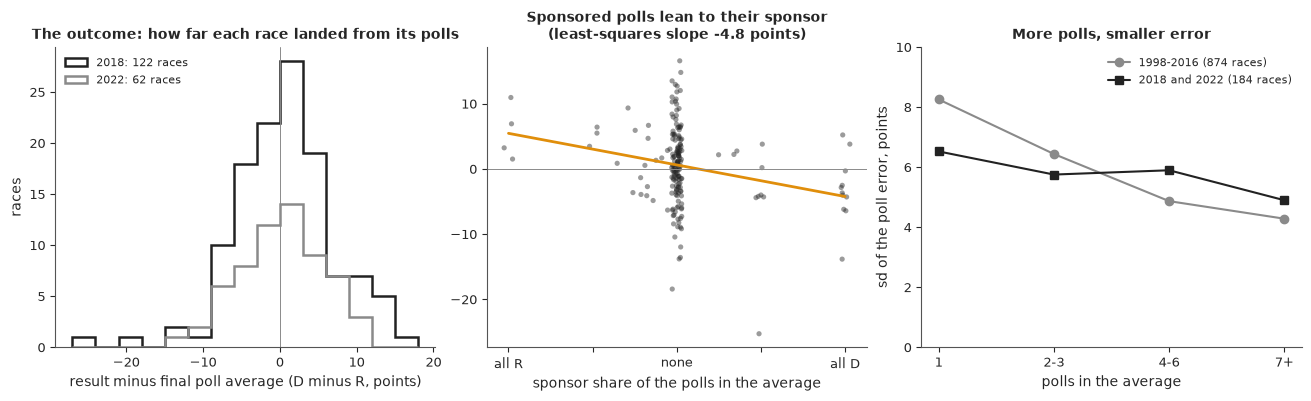

In [6]:
hist = pollerr[(pollerr.cycle < 2018) & ~pollerr.generic & pollerr.type_simple.isin(["House-G", "Sen-G"])].copy()
hist["err"] = -hist.err                                # the file's sign is poll minus result
hist["dev"] = hist.err - hist.groupby(["cycle", "type_simple"]).err.transform("mean")
gen = pollerr[(pollerr.cycle < 2018) & pollerr.generic].groupby("cycle").err.mean()
sen = pollerr[(pollerr.cycle < 2018) & (pollerr.type_simple == "Sen-G")].groupby("cycle").err.mean()
SD_B = float(np.sqrt(np.mean(np.r_[gen.to_numpy(), sen.to_numpy()] ** 2)))    # shared error of a cycle, as in E94
NBINS = [0, 1, 3, 6, 1000]
NLAB = ["1", "2-3", "4-6", "7+"]
hist_sd = hist.groupby(pd.cut(hist.n, NBINS, labels=NLAB), observed=True).dev.agg(["std", "size"])
main_dev = MAIN.y_21 - MAIN.groupby(["cycle", "office"]).y_21.transform("mean")
main_sd = main_dev.groupby(pd.cut(MAIN.n_21, NBINS, labels=NLAB), observed=True).agg(["std", "size"])
print(f"cycle-level shared error, 1998-2016: root mean square {SD_B:.1f} points over {len(gen) + len(sen)} cycle means")
print("sd of a race's poll error around its cycle and office mean, by number of polls in its average")
print(pd.DataFrame({"1998-2016 sd": hist_sd["std"].round(1), "races": hist_sd["size"],
                    "2018 and 2022 sd": main_sd["std"].round(1), "races ": main_sd["size"]}).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
ax = axes[0]
bins = np.arange(-27, 19, 3)
for c, col in ((2018, INK), (2022, MUTED)):
    ax.hist(MAIN.y_21[MAIN.cycle == c], bins=bins, histtype="step", lw=1.8, color=col, label=f"{c}: {int((MAIN.cycle == c).sum())} races")
ax.axvline(0, color=MUTED, lw=0.7)
ax.set_xlabel("result minus final poll average (D minus R, points)")
ax.set_ylabel("races")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("The outcome: how far each race landed from its polls", fontsize=10)
ax = axes[1]
ax.scatter(MAIN.s_21 + rng.uniform(-0.03, 0.03, len(MAIN)), MAIN.y_21, s=14, color=INK, alpha=0.45, edgecolor="none")
xs = np.array([-1, 1])
slope = np.polyfit(MAIN.s_21, MAIN.y_21, 1)
ax.plot(xs, np.polyval(slope, xs), color=CEN_C, lw=2)
ax.axhline(0, color=MUTED, lw=0.7)
ax.set_xticks([-1, -0.5, 0, 0.5, 1], ["all R", "", "none", "", "all D"])
ax.set_xlabel("sponsor share of the polls in the average")
ax.set_title(f"Sponsored polls lean to their sponsor\n(least-squares slope {slope[0]:+.1f} points)", fontsize=10)
ax = axes[2]
x = np.arange(4)
ax.plot(x, hist_sd["std"], "o-", color=MUTED, label=f"1998-2016 ({len(hist)} races)")
ax.plot(x, main_sd["std"], "s-", color=INK, label=f"2018 and 2022 ({len(MAIN)} races)")
ax.set_xticks(x, NLAB)
ax.set_ylim(0, 10)
ax.set_xlabel("polls in the average")
ax.set_ylabel("sd of the poll error, points")
ax.legend(fontsize=8)
ax.set_title("More polls, smaller error", fontsize=10);

The left panel is the outcome: centred near zero, with a few misses beyond 15 points. The middle panel is
the sponsor effect, a slope of about -5 points from polls all sponsored by Republicans to polls all
sponsored by Democrats. The right panel is why the likelihood cannot give every race the same noise. In
1998-2016 a race with one poll in its average missed by 8.3 points (sd) and a race with seven or more by
4.3. In 2018 and 2022 the decline is flatter, 6.5 to 4.9, on far fewer races. We let the scale of the
noise depend on the number of polls and let the data say how strongly.

The same history gives the scale of the error that all polls of a cycle share. Across the 22 cycle-level
mean errors of generic-ballot and Senate polls before 2018, the root mean square is 3.2 points, computed
as in E94. It becomes the prior standard deviation of the shared polling error.

## 2 · Buckets fixed before the election

Commentary sorts candidates into moderates, progressives and DSA candidates. To test the claim we need
groups that existed before the votes were counted. Each list in `e118_ideology` is a Wikipedia revision or
an Internet Archive capture with a timestamp before that cycle's election day, and every entry has a row
in `e118_ideology_flags` with the source, its time and the line that names the person. Nobody is
classified by judgment, ours or the builder's.

There are two kinds of list. **Caucus rosters** (the Congressional Progressive Caucus, the New Democrat
Coalition, the Blue Dog Coalition) can only name sitting members. **Endorsement lists** (Justice
Democrats, Our Revolution and Brand New Congress on one side; the Blue Dog PAC and the NewDem Action Fund
on the other) reach challengers. A nominee is in the **left** bucket when any left list names them and in
the **centre** bucket when any centre list does. A nominee on both carries both effects in the model, and
a nominee on neither is the reference group, "no list".

A blank is not a no. Our Revolution's list could be dated for 2018 only and the NewDem Action Fund's for
2022 and 2026 only, so the buckets are built from the lists that exist in each cycle, and section 6
repeats everything with the lists that exist in all three. The DCCC's Red to Blue programme is in the file
as well; it is party support, not ideology, and enters in section 5. DW-NOMINATE scores (Poole and
Rosenthal's roll-call scaling, from Voteview) exist only for nominees who have served in Congress. A copy
captured before the election exists for 2022 and 2026; for 2018 only today's file does.

In [7]:
src = sources[sources.key.isin(LEFT + CENTRE + ["red_to_blue"])].copy()
src["date"] = src.version_time_utc.str[:10]
when = src.groupby(["key", "cycle"]).date.max().unstack()
rows = []
for f in LEFT + CENTRE:
    r = {"list": LIST_NAME[f], "side": "left" if f in LEFT else "centre", "kind": "roster" if f in ROSTERS else "endorsement"}
    for c in (2018, 2022, 2026):
        if f in when.index and pd.notna(when.loc[f].get(c, np.nan)):
            k = (ALL.cycle == c) & ALL.n_21.notna()
            r[str(c)] = f"{when.loc[f, c]}: {int((ALL.loc[k, 'dx_' + f] == True).sum())}"  # noqa: E712
        else:
            r[str(c)] = "no dated list"
    rows.append(r)
print("source date of each list and the Democratic nominees it names among the races analysed")
print(pd.DataFrame(rows).to_string(index=False))
print("every source is dated before its election day:", bool(src.dated_before_election.all()),
      "| latest:", src.groupby("cycle").version_time_utc.max().str[:10].to_dict())

source date of each list and the Democratic nominees it names among the races analysed
                                    list   side        kind           2018           2022           2026
        Congressional Progressive Caucus   left      roster  2018-10-19: 4  2022-11-05: 7  2026-10-24: 1
                       Justice Democrats   left endorsement  2018-10-30: 6  2022-11-07: 1  2026-10-23: 1
                          Our Revolution   left endorsement  2018-11-04: 8  no dated list  no dated list
                      Brand New Congress   left endorsement  2018-10-17: 1  2022-09-20: 1  no dated list
    DSA officeholders (Wikipedia's list)   left      roster  no dated list  2022-11-02: 0  2026-10-31: 0
                  New Democrat Coalition centre      roster  2018-10-14: 4 2022-11-07: 12  2026-10-23: 9
   Blue Dog Coalition (Wikipedia roster) centre      roster  2018-08-13: 2  2022-11-07: 2  2026-11-02: 3
Blue Dog Coalition (its own member page) centre      roster  2018-10-22: 

every source is dated before its election day: True | latest: {2018.0: '2018-11-04', 2022.0: '2022-11-07', 2026.0: '2026-11-02'}


In [8]:
k21 = ALL.n_21.notna()
bt = pd.crosstab(ALL.cycle[k21], ALL.bucket[k21])[["left", "centre", "both", "no list"]]
bt["left, not seat incumbent"] = ((ALL.bucket == "left") & (ALL.d_inc == 0))[k21].groupby(ALL.cycle[k21]).sum()
bt["left, Senate"] = ((ALL.bucket == "left") & (ALL.office == "S"))[k21].groupby(ALL.cycle[k21]).sum()
bt["centre, Senate"] = ((ALL.bucket == "centre") & (ALL.office == "S"))[k21].groupby(ALL.cycle[k21]).sum()
bt["DW-NOMINATE dated before"] = ALL.dx_nominate_dim1.notna()[k21].groupby(ALL.cycle[k21]).sum()
bt["DW-NOMINATE today"] = ALL.dx_nominate_dim1_posthoc.notna()[k21].groupby(ALL.cycle[k21]).sum()
print(bt.to_string())

bucket  left  centre  both  no list  left, not seat incumbent  left, Senate  centre, Senate  DW-NOMINATE dated before  DW-NOMINATE today
cycle                                                                                                                                   
2018      14      17     1       90                        10             1               1                         0                 30
2022       8      21     1       32                         3             2               1                        36                 36
2026       1      34     1       25                         1             0               1                        16                 16


This table is the thin part of the analysis, and it is better said here than found later in an interval.
Of the 184 races, 22 have a Democratic nominee on a left list only (14 in 2018, 8 in 2022), 38 on a centre
list only, 2 on both and 122 on none. Thirteen of the 22 do not hold the seat they are running for. Three
of the 22 are Senate nominees, and two of the 38. The third group of the claim, DSA candidates, is empty:
Wikipedia's list of DSA officeholders can be dated for 2022 and 2026 and names no Democratic nominee in
these races. So whatever the model says about "left", it says about members of the Progressive Caucus and
nominees endorsed by three organisations, almost all in House races and two thirds of them in 2018.

2026 is thinner still, which matters in section 8: of its 61 races with a final poll, one nominee is on a
left list only and 34 are on a centre list.

In [9]:
ev = flags[(flags.side == "D") & flags.flag.isin(LEFT)].merge(MAIN[["cycle", "race"]], on=["cycle", "race"])
ev["source"] = ev.flag.map(LIST_NAME) + ", " + ev.source_time_utc.str[:10]
shown = ev.groupby(["cycle", "race", "name"]).source.apply("; ".join).reset_index()
print(f"{len(shown)} Democratic nominees on a left list among the {len(MAIN)} races, with the list and the date of the source")
print(shown.to_string(index=False))

24 Democratic nominees on a left list among the 184 races, with the list and the date of the source
 cycle  race                    name                                                                                    source
  2018 CA-50     Campa-Najjar, Ammar                                 Justice Democrats, 2018-10-30; Our Revolution, 2018-11-04
  2018 IA-02          Loebsack, Dave                                              Congressional Progressive Caucus, 2018-10-19
  2018 IA-04          Scholten, J.D.                                                                Our Revolution, 2018-11-04
  2018 IN-09             Watson, Liz                                                                Our Revolution, 2018-11-04
  2018 KS-04      Thompson, James A. Brand New Congress, 2018-10-17; Justice Democrats, 2018-10-30; Our Revolution, 2018-11-04
  2018 ME-01        Pingree, Chellie                                              Congressional Progressive Caucus, 2018-10-19
  2018 MI-0

The table lists the nominees behind the left bucket, each with the list and the date of the source that
names them. That is all this notebook says about any individual; the centre bucket can be listed the same
way from `e118_ideology_flags`.

## 3 · The comparison a commentator makes

In its simplest form the claim is a difference of two means: the average poll error of centre-list
nominees minus that of left-list nominees. If the commentators are right it is positive. We compute it
with a bootstrap interval, leaving out the two nominees who are on both kinds of list.

         races    mean      sd
bucket                        
left        22    0.95    7.30
centre      38    0.77    5.30
both         2 too few too few
no list    122    0.23    6.21
                                  left  centre  centre minus left  90% lower  90% upper
races                                                                                  
2018                                14      17               0.06       -4.0        4.4
2022                                 8      21              -0.66       -3.9        2.5
both cycles                         22      38              -0.18       -2.9        2.6
both cycles, House                  19      36               0.82       -2.2        3.9
both cycles, not seat incumbents    13      25              -2.15       -6.4        2.2


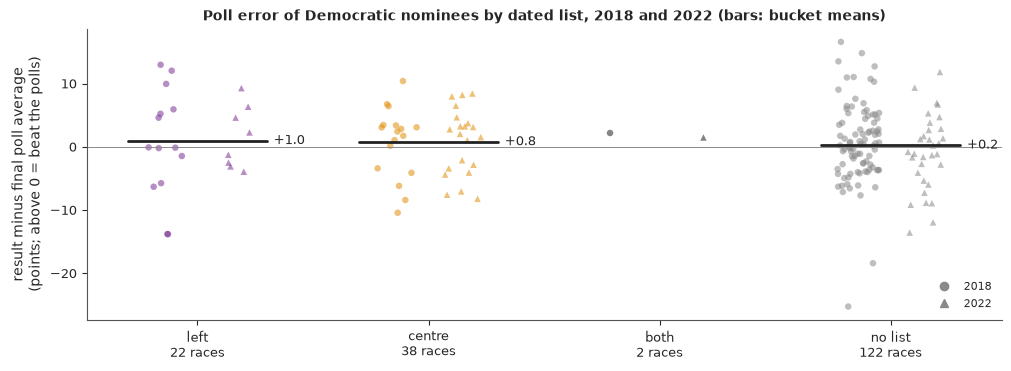

In [10]:
def naive_contrast(y, left, centre):
    """Mean poll error of centre-list nominees minus that of left-list nominees (those on both are left out)."""
    a, b = y[centre & ~left], y[left & ~centre]
    return a.mean() - b.mean() if len(a) and len(b) else np.nan


def bootstrap_contrast(y, left, centre, n=4000, seed=RANDOM_SEED):
    g = np.random.default_rng(seed)
    a, b = y[centre & ~left], y[left & ~centre]
    return (g.choice(a, (n, len(a))).mean(1) - g.choice(b, (n, len(b))).mean(1))


yM, LM, CM = MAIN.y_21.to_numpy(), MAIN.left.to_numpy(), MAIN.centre.to_numpy()
bm = MAIN.groupby("bucket").y_21.agg(races="size", mean="mean", sd="std").round(2).loc[["left", "centre", "both", "no list"]]
bm.loc[bm.races < MIN_BUCKET, ["mean", "sd"]] = np.nan
print(bm.to_string(na_rep="too few"))
rows = []
for lab, k in (("2018", MAIN.cycle == 2018), ("2022", MAIN.cycle == 2022), ("both cycles", MAIN.cycle > 0),
               ("both cycles, House", MAIN.office == "H"), ("both cycles, not seat incumbents", MAIN.d_inc == 0)):
    k = k.to_numpy()
    bs = bootstrap_contrast(yM[k], LM[k], CM[k])
    rows.append({"races": lab, "left": int((LM & ~CM & k).sum()), "centre": int((CM & ~LM & k).sum()),
                 "centre minus left": round(naive_contrast(yM[k], LM[k], CM[k]), 2),
                 "90% lower": round(np.quantile(bs, 0.05), 1), "90% upper": round(np.quantile(bs, 0.95), 1)})
NAIVE = pd.DataFrame(rows).set_index("races")
print(NAIVE.to_string())
NAIVE_BS = bootstrap_contrast(yM, LM, CM)

fig, ax = plt.subplots(figsize=(10, 3.6))
order = [("left", LEFT_C), ("centre", CEN_C), ("both", INK), ("no list", MUTED)]
for i, (b, col) in enumerate(order):
    s = MAIN[MAIN.bucket == b]
    for c, mk, dx in ((2018, "o", -0.14), (2022, "^", 0.14)):
        v = s.y_21[s.cycle == c]
        ax.scatter(i + dx + rng.uniform(-0.09, 0.09, len(v)), v, s=22, marker=mk, color=col, alpha=0.55, edgecolor="none")
    if len(s) >= MIN_BUCKET:
        ax.plot([i - 0.3, i + 0.3], [s.y_21.mean()] * 2, color=INK, lw=2)
        ax.text(i + 0.33, s.y_21.mean(), f"{s.y_21.mean():+.1f}", va="center", fontsize=9)
ax.axhline(0, color=MUTED, lw=0.7)
ax.set_xticks(range(4), [f"{b}\n{int((MAIN.bucket == b).sum())} races" for b, _ in order])
ax.set_ylabel("result minus final poll average\n(points; above 0 = beat the polls)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=MUTED, label="2018"), Line2D([], [], marker="^", ls="", color=MUTED, label="2022")],
          fontsize=8, loc="lower right")
ax.set_title("Poll error of Democratic nominees by dated list, 2018 and 2022 (bars: bucket means)", fontsize=10);

With labels fixed before the election there is no gap. Left-list nominees beat their final polls by about
1 point on average and centre-list nominees by 0.8. The difference is -0.2 points, and its 90% bootstrap
interval runs from -2.9 to +2.6. Neither cycle shows one alone (+0.1 in 2018, -0.7 in 2022).

The subsets already hint at how such comparisons get made. Among House races the gap is +0.8, in the
commentators' direction. Among nominees who do not hold the seat it is -2.1, against them. Both intervals
are more than 6 points wide. The figure shows why: the bucket means lie within a point of each other,
while single races are spread over 5 to 7 points around them.

A difference in means cannot settle the matter in either direction. It ignores that sponsored polls lean,
that a race with one poll is noisier than a race with ten, that all polls of a year can miss together, and
that the buckets differ in district, opponent and party support. The next two sections add these in turn.

## 4 · A model of poll error

For race $i$ in cycle $c$, for office $o$ (House or Senate), in state $s$, the poll error is modelled as

$$
y_i \sim \mathcal N(\mu_i,\ \sigma_i),\qquad
\mu_i = b_c + d_{c,o} - \delta\,\text{sponsor}_i + \theta_L L_i + \theta_C C_i
        + x_i^{\top}\beta + z_i^{\top}\gamma + \kappa\,u_{c,s} .
$$

$b_c \sim \mathcal N(0, 3.2)$ is the cycle's **shared polling error**, with the prior scale from
1998-2016, and $d_{c,o}$ lets House and Senate polls of one year miss differently (zero-sum over the two
offices, sd 2). $\delta \sim \mathcal N(2, 2)$ is the lean of sponsored polls, with E94's prior: a poll
average made only of Democratic-sponsored polls overstates the Democrat by $\delta$, so the outcome falls
by $\delta$. $L_i$ and $C_i$ mark the left and centre buckets, with
$\theta_L, \theta_C \sim \mathcal N(0, 3)$, and the quantity of interest is the **contrast**

$$
\Delta = \theta_C - \theta_L ,
$$

the poll error of a centre-list nominee minus that of a left-list nominee, other things equal. The claim
says $\Delta > 0$. The covariates $x_i$ (district, incumbency, opponent) and $z_i$ (party support) are
described in section 5; $\beta_k \sim \mathcal N(0, 2)$, and the sixteen party-support coefficients share
a scale, $\gamma_k \sim \mathcal N(0, s_\gamma)$ with $s_\gamma \sim \text{HalfNormal}(1)$. Every
covariate is centred, so $b_c$ is the error for a no-list nominee with average covariates and unsponsored
polls. $u_{c,s} \sim \mathcal N(0,1)$ is shared by all races of a state in one year, because they share
pollsters and turnout: without it, ten California districts missing together would count as ten
independent pieces of evidence.

The noise has a part that no number of polls removes and a part that averages out over the $n_i$ polls of
a race:

$$
\sigma_i^2 = \sigma_{o}^2 + \tau^2 / n_i .
$$

In this first version the three scales have their own priors, $\sigma_o \sim \text{HalfNormal}(4)$,
$\tau \sim \text{HalfNormal}(6)$ and $\kappa \sim \text{HalfNormal}(3)$.

In [11]:
def design(F, key="21", ref=None):
    """Arrays for the model from rows of the frame. `ref` (a fitted design) supplies the centring means; a
    covariate that is blank (no dated source in that cycle) is set to the mean, so it contributes nothing."""
    plain = PLAIN["fund"] + PLAIN["opp"]
    Xp, Xm = F[plain].to_numpy(float), F[MONEY].to_numpy(float)
    mp = np.nanmean(Xp, 0) if ref is None else ref["mean_p"]
    mm = np.nanmean(Xm, 0) if ref is None else ref["mean_m"]
    Xp, Xm = np.where(np.isnan(Xp), mp, Xp) - mp, np.where(np.isnan(Xm), mm, Xm) - mm
    cycles = sorted(F.cycle.unique())
    sc = (F.cycle.astype(str) + " " + F.state).to_numpy(dtype=object)
    scl = sorted(set(sc))
    return {"F": F, "y": F[f"y_{key}"].to_numpy(float), "n": F[f"n_{key}"].to_numpy(float), "s": F[f"s_{key}"].to_numpy(float),
            "L": F.left.to_numpy(float), "C": F.centre.to_numpy(float), "Xp": Xp, "Xm": Xm, "mean_p": mp, "mean_m": mm,
            "plain": plain, "cycles": cycles, "ci": F.cycle.map({c: i for i, c in enumerate(cycles)}).to_numpy(),
            "oi": (F.office == "S").to_numpy().astype(int), "scl": scl, "si": np.array([scl.index(v) for v in sc]),
            "race": (F.cycle.astype(str) + " " + F.race).to_numpy(dtype=object)}


def build_model(D, blocks=("fund", "opp", "party"), likelihood="t", scales="shares", masked=False, extra=None):
    """Poll error of a race: cycle and office shifts, sponsor lean, covariate blocks, ideology lists, a
    state-and-cycle effect and noise that shrinks with the number of polls.

    scales="direct" samples three standard deviations; "shares" samples a total and its split (section 4.2).
    masked=True writes the likelihood with 0/1 row weights so one compiled model serves many refits."""
    plain = [c for b in ("fund", "opp") if b in blocks for c in PLAIN[b]]
    jp = [D["plain"].index(c) for c in plain]
    coords = {"cycle": D["cycles"], "office": ["H", "S"], "state_cycle": D["scl"], "race": D["race"],
              "bucket": ["left", "centre"], "part": ["state", "race", "poll"]}
    if plain:
        coords["x"] = plain
    if "party" in blocks:
        coords["money"] = MONEY
    if extra is not None:
        coords["extra"] = list(extra.columns)
    ok = ~np.isnan(D["y"])
    with pm.Model(coords=coords) as m:
        L = pm.Data("L", D["L"], dims="race")
        C = pm.Data("C", D["C"], dims="race")
        y = pm.Data("y_obs", np.where(ok, D["y"], 0.0), dims="race")
        n = pm.Data("n_polls", np.where(ok, D["n"], 1.0), dims="race")
        s = pm.Data("sponsor", np.where(ok, D["s"], 0.0), dims="race")
        w = pm.Data("w", ok.astype(float), dims="race")
        b = pm.Normal("b", 0, SD_B, dims="cycle")                               # shared polling error
        d = pm.ZeroSumNormal("d", sigma=2.0, dims=("cycle", "office"))          # House against Senate
        delta = pm.Normal("delta", 2.0, 2.0)                                    # sponsor lean
        theta = pm.Normal("theta", 0, 3.0, dims="bucket")
        pm.Deterministic("contrast", theta[1] - theta[0])                       # centre minus left
        mu = b[D["ci"]] + d[D["ci"], D["oi"]] - delta * s + theta[0] * L + theta[1] * C
        if plain:
            beta = pm.Normal("beta", 0, 2.0, dims="x")
            mu = mu + pt.dot(D["Xp"][:, jp], beta)
        if "party" in blocks:
            s_money = pm.HalfNormal("s_money", 1.0)
            gamma = pm.Deterministic("gamma", s_money * pm.Normal("z_money", 0, 1, dims="money"), dims="money")
            mu = mu + pt.dot(D["Xm"], gamma)
        if extra is not None:
            xe = extra.to_numpy(float)
            mu = mu + pt.dot(xe - xe.mean(0), pm.Normal("beta_extra", 0, 2.0, dims="extra"))
        u = pm.Normal("u", 0, 1, dims="state_cycle")
        if scales == "direct":
            sigma = pm.HalfNormal("sigma", 4.0, dims="office")
            tau = pm.HalfNormal("tau", 6.0)
            mu = mu + pm.HalfNormal("s_state", 3.0) * u[D["si"]]
            sd = pt.sqrt(sigma[D["oi"]] ** 2 + tau**2 / n)
        else:
            S = pm.HalfNormal("S", 7.0, dims="office")                         # scale of a one-poll race
            share = pm.Dirichlet("share_of_variance", np.array([2.0, 2.0, 2.0]), dims="part")
            mu = mu + S[D["oi"]] * pt.sqrt(share[0]) * u[D["si"]]
            sd = S[D["oi"]] * pt.sqrt(share[1] + share[2] / n)
        dist = pm.Normal.dist(mu, sd) if likelihood == "normal" else pm.StudentT.dist(nu=pm.Gamma("nu", 2.0, 0.1), mu=mu, sigma=sd)
        if masked:
            pm.Potential("likelihood", pt.sum(w * pm.logp(dist, y)))
        elif likelihood == "normal":
            pm.Normal("y", mu, sd, observed=D["y"], dims="race")
        else:
            pm.StudentT("y", nu=m["nu"], mu=mu, sigma=sd, observed=D["y"], dims="race")
    return m


def diagnostics(idata):
    """Divergences, and the worst r_hat and ESS over variables, one variable at a time (see E94)."""
    rh, es = az.rhat(idata.posterior), az.ess(idata.posterior)
    return {"divergences": int(idata.sample_stats["diverging"].sum()),
            "max r_hat": round(max(float(rh[v].max()) for v in rh.data_vars), 3),
            "worst r_hat": max(rh.data_vars, key=lambda v: float(rh[v].max())),
            "min ESS": int(min(float(es[v].min()) for v in es.data_vars)),
            "lowest ESS": min(es.data_vars, key=lambda v: float(es[v].min())),
            "tuning": int(idata.posterior.attrs.get("tuning_steps", -1))}


def fit(D, **kw):
    t0 = time.time()
    with build_model(D, **kw):
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=0.95)
    return idata, {"seconds": round(time.time() - t0, 1), **diagnostics(idata)}


def contrast_row(c):
    c = np.asarray(c).ravel()
    return {"centre minus left": round(float(np.median(c)), 2), "90% lower": round(float(np.quantile(c, 0.05)), 1),
            "90% upper": round(float(np.quantile(c, 0.95)), 1), "P(centre > left)": round(float((c > 0).mean()), 2)}


def ess_of(c):
    """Bulk ESS of flat draws stored chain after chain (4 chains)."""
    return int(az.ess(xr.DataArray(np.asarray(c).reshape(4, -1), dims=("chain", "draw"))))


def tail_probabilities(c, by=(2, 3)):
    c = np.asarray(c).ravel()
    return {f"P(centre ahead by {k}+ points)": round(float((c >= k).mean()), 3) for k in by} | {
        f"P(left ahead by {k}+ points)": round(float((c <= -k).mean()), 3) for k in by}


DM = design(MAIN)
print(f"{len(MAIN)} races, {len(DM['scl'])} state-and-cycle groups, "
      f"{len(DM['plain'])} fundamentals and opponent covariates, {len(MONEY)} party-support covariates")
sizes = pd.Series(DM["si"]).value_counts()
print(f"state-and-cycle groups holding a single race: {int((sizes == 1).sum())} of {len(sizes)}; "
      f"races with a single poll: {int((DM['n'] == 1).sum())} of {len(MAIN)}")
print(f"prior sd of a cycle's shared error: {SD_B:.1f} points (from 1998-2016)")

184 races, 73 state-and-cycle groups, 8 fundamentals and opponent covariates, 16 party-support covariates
state-and-cycle groups holding a single race: 29 of 73; races with a single poll: 94 of 184
prior sd of a cycle's shared error: 3.2 points (from 1998-2016)


### 4.1 Do the priors describe poll errors?

Before fitting we draw data sets from the priors and compare them with knowledge from outside the 184
races: the spread of race-level poll errors in 1998-2016, for races with one poll and with four or more,
and the size of gap the prior allows between the buckets.

spread of race poll errors across a data set (IQR / 1.349, points): median and 90% interval over prior draws
prior predictive: one poll 8.9 [5.1, 15.0], four or more polls 7.9 [4.3, 14.6]
1998-2016:        one poll 7.4, four or more polls 4.3
prior of the contrast (centre minus left): sd 4.2, 90% interval [-6.9, 6.8]
prior predictive of the difference in means: 90% interval [-7.5, 8.9]


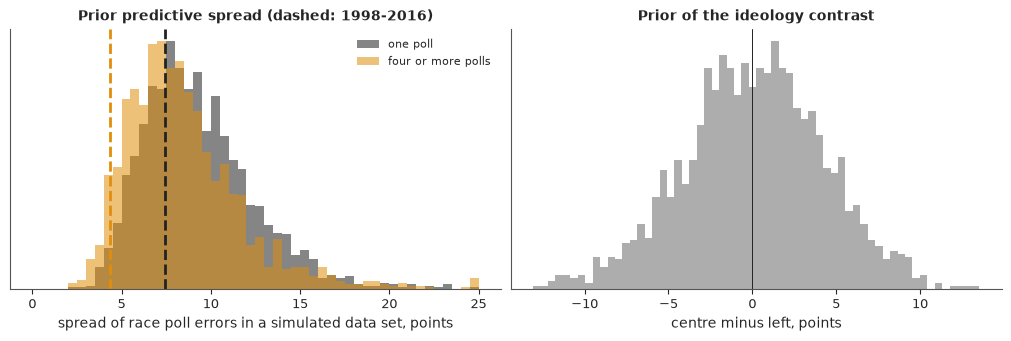

In [12]:
def robust_sd(a, axis=-1):
    q75, q25 = np.nanquantile(a, [0.75, 0.25], axis=axis)
    return (q75 - q25) / 1.349


def prior_spread(**kw):
    """Spread of simulated race errors with one poll and with four or more, and the prior of the contrast."""
    with build_model(DM, **kw):
        prior = pm.sample_prior_predictive(draws=2000, random_seed=RANDOM_SEED)
    yp = prior.prior_predictive["y"].stack(s=("chain", "draw")).transpose("s", ...).values
    yp = np.where(np.isfinite(yp), yp, np.nan)
    return (robust_sd(yp[:, DM["n"] == 1]), robust_sd(yp[:, DM["n"] >= 4]), prior.prior["contrast"].values.ravel(),
            np.array([naive_contrast(v, LM, CM) for v in yp[:500]]))


def show_spread(lab, one, many):
    print(f"{lab}: one poll {np.median(one):.1f} [{np.quantile(one, 0.05):.1f}, {np.quantile(one, 0.95):.1f}], "
          f"four or more polls {np.median(many):.1f} [{np.quantile(many, 0.05):.1f}, {np.quantile(many, 0.95):.1f}]")


pp_one, pp_many, pc, pn = prior_spread(likelihood="normal", scales="direct")
h_one, h_many = robust_sd(hist.dev[hist.n == 1].to_numpy()), robust_sd(hist.dev[hist.n >= 4].to_numpy())
print("spread of race poll errors across a data set (IQR / 1.349, points): median and 90% interval over prior draws")
show_spread("prior predictive", pp_one, pp_many)
print(f"1998-2016:        one poll {h_one:.1f}, four or more polls {h_many:.1f}")
print(f"prior of the contrast (centre minus left): sd {pc.std():.1f}, 90% interval [{np.quantile(pc, 0.05):.1f}, {np.quantile(pc, 0.95):.1f}]")
print(f"prior predictive of the difference in means: 90% interval [{np.nanquantile(pn, 0.05):.1f}, {np.nanquantile(pn, 0.95):.1f}]")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
ax = axes[0]
bins = np.linspace(0, 25, 51)
ax.hist(np.clip(pp_one, 0, 25), bins=bins, color=INK, alpha=0.55, density=True, label="one poll")
ax.hist(np.clip(pp_many, 0, 25), bins=bins, color=CEN_C, alpha=0.55, density=True, label="four or more polls")
ax.axvline(h_one, color=INK, lw=2, ls="--")
ax.axvline(h_many, color=CEN_C, lw=2, ls="--")
ax.set_xlabel("spread of race poll errors in a simulated data set, points")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title("Prior predictive spread (dashed: 1998-2016)", fontsize=10)
ax = axes[1]
ax.hist(pc, bins=60, color=MUTED, alpha=0.7, density=True)
ax.axvline(0, color=INK, lw=0.7)
ax.set_xlabel("centre minus left, points")
ax.set_yticks([])
ax.set_title("Prior of the ideology contrast", fontsize=10);

A simulated data set has a spread of about 9 points among its one-poll races (90% of draws between 5 and
15) and about 8 among its well-polled ones (4 to 15). History's 7.4 is inside the first range, a little
below its median; its 4.3 sits at the low edge of the second, so the priors err on the wide side. An
earlier draft with wider priors on the covariates (sd 3 each, a money scale of 1.5) and on the noise put
the well-polled history outside the range, and the priors above are the tightened ones. The prior on the
two list effects was left at sd 3 on purpose. It gives the contrast a prior sd of 4.2 and a 90% range of
about -7 to +7 points: room for a claim of any plausible size, in either direction.

### 4.2 Failure 1: three variances the data cannot separate

The three scales of the noise share one job. In 29 of the 73 state-and-cycle groups there is a single
race, and there the state effect and the race's own error are one number. In 94 of the 184 races there is
a single poll, and there the race's own error and the poll's noise are one number. The data fix the total
well and its division poorly, so the posterior has ridges that run into zero along each scale, and a
sampler tuned for the bulk takes steps that are too long near those walls.

The remedy is to sample what the data do know. Let $S_o$ be the scale of the whole error of a one-poll
race, and let $\pi = (\pi_{\text{state}}, \pi_{\text{race}}, \pi_{\text{poll}})$ be the shares of its
variance:

$$
S_o \sim \text{HalfNormal}(7),\qquad \pi \sim \text{Dirichlet}(2, 2, 2),\qquad
\kappa_o = S_o\sqrt{\pi_{\text{state}}},\qquad
\sigma_i^2 = S_o^2\,\big(\pi_{\text{race}} + \pi_{\text{poll}} / n_i\big).
$$

The structure is the same: a state effect, race noise, and poll noise that averages out. The trade-off
between the parts now lives inside a triangle, and $S_o$ is nearly independent of it. We fit the model
both ways, with normal errors.

In [13]:
t0 = time.time()
fit_direct, diag_direct = fit(DM, likelihood="normal", scales="direct")
fit_normal, diag_normal = fit(DM, likelihood="normal", scales="shares")
TIMES["two parameterisations"] = time.time() - t0
print(pd.DataFrame({"three standard deviations": diag_direct, "total and shares": diag_normal}).T.to_string())
es = az.ess(fit_direct.posterior)
print("ESS, three standard deviations:", {v: [int(e) for e in np.atleast_1d(es[v].values)] for v in ("sigma", "tau", "s_state")})
es = az.ess(fit_normal.posterior)
print("ESS, total and shares:         ", {v: [int(e) for e in np.atleast_1d(es[v].values)] for v in ("S", "share_of_variance")})
for lab, f in (("three standard deviations", fit_direct), ("total and shares", fit_normal)):
    print(lab, contrast_row(f.posterior["contrast"].values))
print(az.summary(fit_normal, var_names=["S"], round_to=2).to_string())
print(az.summary(fit_normal, var_names=["share_of_variance"], round_to=2).to_string())
show_spread("prior predictive spread, total and shares", *prior_spread(likelihood="normal", scales="shares")[:2])

                          seconds divergences max r_hat worst r_hat min ESS lowest ESS tuning
three standard deviations     3.8           4     1.014         tau     234      sigma    400
total and shares              3.1           0     1.005           u     945    s_money    400
ESS, three standard deviations: {'sigma': [418, 234], 'tau': [340], 's_state': [385]}
ESS, total and shares:          {'S': [2423, 2923], 'share_of_variance': [1270, 1742, 2757]}
three standard deviations {'centre minus left': -1.27, '90% lower': -3.7, '90% upper': 1.2, 'P(centre > left)': 0.2}
total and shares {'centre minus left': -1.04, '90% lower': -3.4, '90% upper': 1.3, 'P(centre > left)': 0.22}
      mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
S[H]  5.89  0.43      5.25      6.62   2423.61   2347.62    1.0       0.01     0.01
S[S]  4.88  0.64      3.94      5.97   2923.65   2968.54    1.0       0.01     0.01
                          mean    sd  eti89_lb  eti89_ub  ess

prior predictive spread, total and shares: one poll 7.9 [4.0, 14.9], four or more polls 7.9 [3.8, 15.0]


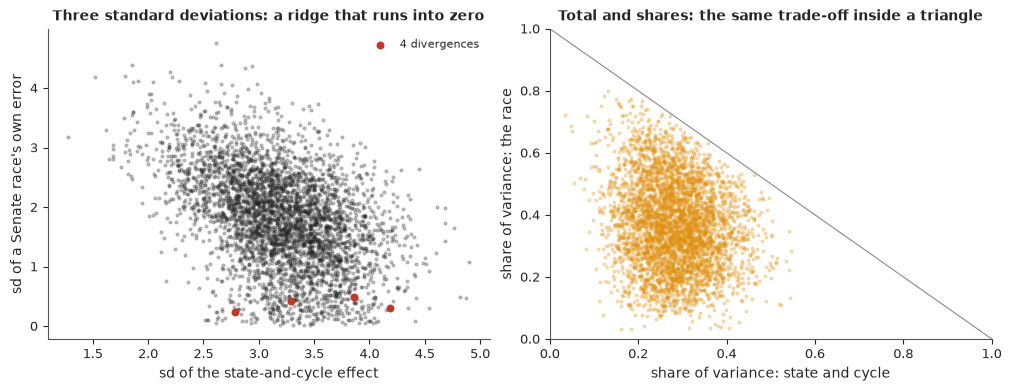

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
pd_ = az.extract(fit_direct, var_names=["sigma", "s_state"])
dv = fit_direct.sample_stats["diverging"].stack(sample=("chain", "draw")).values
sS = pd_["sigma"].sel(office="S").values
ax = axes[0]
ax.scatter(pd_["s_state"].values, sS, s=4, color=INK, alpha=0.25)
ax.scatter(pd_["s_state"].values[dv], sS[dv], s=22, color=R_C, label=f"{int(dv.sum())} divergences")
ax.set_xlabel("sd of the state-and-cycle effect")
ax.set_ylabel("sd of a Senate race's own error")
ax.legend(fontsize=8)
ax.set_title("Three standard deviations: a ridge that runs into zero", fontsize=10)
pn_ = az.extract(fit_normal, var_names=["share_of_variance"])
ax = axes[1]
ax.scatter(pn_.sel(part="state").values, pn_.sel(part="race").values, s=4, color=CEN_C, alpha=0.25)
ax.plot([0, 1], [1, 0], color=MUTED, lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("share of variance: state and cycle")
ax.set_ylabel("share of variance: the race")
ax.set_title("Total and shares: the same trade-off inside a triangle", fontsize=10)
del fit_direct;

As first written, the fit finishes with divergences (between 4 and 20 across runs of this notebook) and an
effective sample size in the low hundreds for $\sigma_o$, $\tau$ and $\kappa$. The left panel shows one of
the ridges, with the divergent transitions marked.

With the total and its shares there are no divergences, $\hat R$ is 1.005 at worst and every scale and
share has an effective sample size above 1,200. The answer to the question did not depend on it: the
contrast is about -1.2 before and -1.0 after, with nearly the same interval. What the data know is the
total, 5.9 points for a one-poll House race and 4.9 for a Senate race. The shares come out near 0.3, 0.35
and 0.35, each with an interval that covers most of what the prior allowed: 184 races cannot say much
about how the error divides, which is exactly why sampling the division directly went badly. The prior
predictive spread under this parameterisation is 8 points (4 to 15) for both kinds of race, with history
inside.

### 4.3 Failure 2: the tails

A posterior predictive check asks whether the 184 observed errors look like draws from the fitted model.
One detail matters here. PyMC's posterior predictive keeps the fitted state-and-cycle effects, and with 29
groups of one race, each of those races would then explain itself. The function `predict` below draws the
state effects afresh, so the check is of the model's claim about a new set of races like these. We look at
the coverage of its intervals, the largest miss and the excess kurtosis. The same function serves section
8, where it predicts a cycle the model has not seen.

                                                        normal                                  Student-t
90% interval covers                                      0.918                                      0.908
50% interval covers                                      0.571                                      0.571
largest |error|      25.3 against 18.4 [14.8, 23.8], p = 0.018  25.3 against 19.0 [15.0, 26.8], p = 0.081
sd                       6.1 against 6.2 [5.4, 7.0], p = 0.539      6.1 against 6.1 [5.3, 7.0], p = 0.500
excess kurtosis         1.5 against 0.0 [-0.5, 0.8], p = 0.004     1.5 against 0.2 [-0.4, 1.5], p = 0.051
    mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
nu  16.6  11.4       5.2      38.2    3060.8    2902.0    1.0        0.2      0.3
normal    {'centre minus left': -1.04, '90% lower': -3.4, '90% upper': 1.3, 'P(centre > left)': 0.22}
Student-t {'centre minus left': -0.97, '90% lower': -3.3, '90% upper': 1.3, 'P(centre > left)': 0.

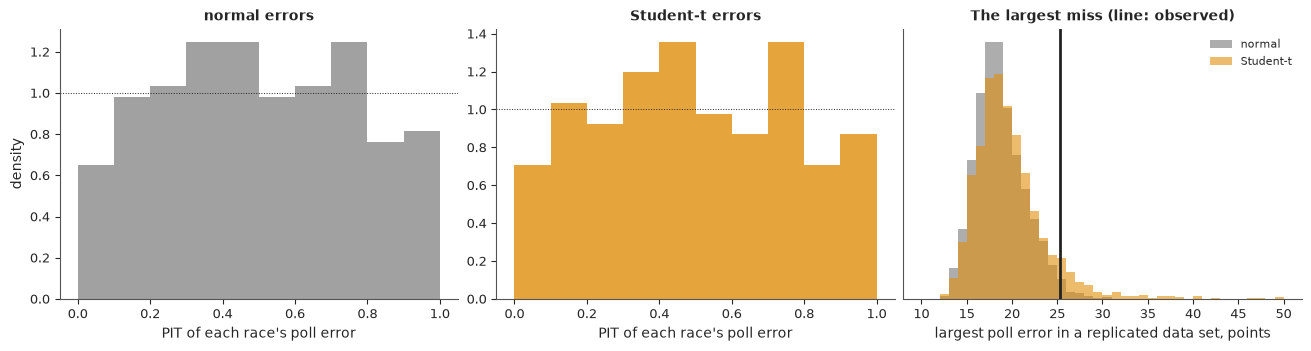

In [15]:
def draws_of(idata, n=2000):
    """Posterior draws as plain arrays, first axis the draw."""
    post = az.extract(idata, num_samples=n, random_seed=RANDOM_SEED)
    T = lambda v, *dims: post[v].transpose("sample", *dims).values  # noqa: E731
    out = {"b": T("b", "cycle"), "d": T("d", "cycle", "office"), "delta": T("delta"), "theta": T("theta", "bucket"),
           "S": T("S", "office"), "share": T("share_of_variance", "part")}
    for v, dim in (("beta", "x"), ("gamma", "money"), ("beta_extra", "extra")):
        if v in post:
            out[v] = T(v, dim)
    if "nu" in post:
        out["nu"] = T("nu")
    return out


def predict(dr, D, new_cycle=None, zero_ideology=False, seed=RANDOM_SEED):
    """Replicated poll errors (draws x races). State-and-cycle effects are always drawn afresh: keeping the
    fitted ones would let each lone race explain itself. new_cycle=sd draws the cycle's shared error and its
    House-Senate split from their priors, for a cycle the model has not seen."""
    g = np.random.default_rng(seed)
    k = len(dr["delta"])
    if new_cycle is not None:
        dh = g.normal(0, 2.0 / np.sqrt(2), k)[:, None]             # ZeroSumNormal(2) over two offices
        level = g.normal(0, new_cycle, k)[:, None] + np.where(D["oi"] == 1, -dh, dh)
    else:
        level = dr["b"][:, D["ci"]] + dr["d"][:, D["ci"], D["oi"]]
    mu = level - dr["delta"][:, None] * D["s"]
    if not zero_ideology:
        mu = mu + dr["theta"][:, [0]] * D["L"] + dr["theta"][:, [1]] * D["C"]
    if "beta" in dr:
        mu = mu + dr["beta"] @ D["Xp"].T
    if "gamma" in dr:
        mu = mu + dr["gamma"] @ D["Xm"].T
    S = dr["S"][:, D["oi"]]
    mu = mu + S * np.sqrt(dr["share"][:, [0]]) * g.standard_normal((k, len(D["scl"])))[:, D["si"]]
    eps = g.standard_t(dr["nu"][:, None], size=mu.shape) if "nu" in dr else g.standard_normal(mu.shape)
    return mu + S * np.sqrt(dr["share"][:, [1]] + dr["share"][:, [2]] / D["n"]) * eps


def check(rep, y):
    lo, hi = np.quantile(rep, [0.05, 0.95], 0)
    lo5, hi5 = np.quantile(rep, [0.25, 0.75], 0)
    out = {"90% interval covers": round(float(np.mean((y >= lo) & (y <= hi))), 3),
           "50% interval covers": round(float(np.mean((y >= lo5) & (y <= hi5))), 3)}
    for lab, f in (("largest |error|", lambda a: np.abs(a).max(-1)), ("sd", lambda a: a.std(-1)),
                   ("excess kurtosis", lambda a: stats.kurtosis(a, axis=-1))):
        r = f(rep)
        out[lab] = f"{f(y):.1f} against {np.median(r):.1f} [{np.quantile(r, 0.05):.1f}, {np.quantile(r, 0.95):.1f}], p = {np.mean(r >= f(y)):.3f}"
    return out


t0 = time.time()
FULL, diag_full = fit(DM, likelihood="t")
TIMES["full model"] = time.time() - t0
DR_N, DR = draws_of(fit_normal), draws_of(FULL)
rep_n, rep_t = predict(DR_N, DM), predict(DR, DM)
print(pd.DataFrame({"normal": check(rep_n, yM), "Student-t": check(rep_t, yM)}).to_string())
print(az.summary(FULL, var_names=["nu"], round_to=1).to_string())
print("normal   ", contrast_row(fit_normal.posterior["contrast"].values))
print("Student-t", contrast_row(FULL.posterior["contrast"].values))
NORMAL_CONTRAST = fit_normal.posterior["contrast"].values.ravel()
del fit_normal

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (lab, rep, col) in zip(axes[:2], (("normal", rep_n, MUTED), ("Student-t", rep_t, CEN_C))):
    pit = (rep < yM).mean(0)
    ax.hist(pit, bins=10, range=(0, 1), color=col, alpha=0.8, density=True)
    ax.axhline(1, color=INK, lw=0.7, ls=":")
    ax.set_xlabel("PIT of each race's poll error")
    ax.set_title(f"{lab} errors", fontsize=10)
axes[0].set_ylabel("density")
ax = axes[2]
bins = np.linspace(10, 50, 41)
ax.hist(np.clip(np.abs(rep_n).max(1), 10, 50), bins=bins, color=MUTED, alpha=0.7, density=True, label="normal")
ax.hist(np.clip(np.abs(rep_t).max(1), 10, 50), bins=bins, color=CEN_C, alpha=0.6, density=True, label="Student-t")
ax.axvline(np.abs(yM).max(), color=INK, lw=2)
ax.set_xlabel("largest poll error in a replicated data set, points")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title("The largest miss (line: observed)", fontsize=10);

The normal model gets the spread right and the shape wrong. Its largest replicated miss is 18 points in
the median and reaches 25 in about 2% of replications; the excess kurtosis of the data, 1.5, is matched or
exceeded in fewer than 1%. Real poll errors have a few very large misses, in thinly polled and lopsided
districts, that a normal distribution calls impossible, and a likelihood that calls them impossible lets
them pull the bucket means around.

So the likelihood becomes a Student-t with the degrees of freedom estimated,
$\nu \sim \text{Gamma}(2, 0.1)$ (Juárez and Steel 2010). This change was made after seeing the check, not
planned. It helps without being a cure: $\nu$ comes out near 15 with a wide interval, the largest miss is
now matched in about 8% of replications and the kurtosis in 5 to 7%. Both models put a little too much
probability in the middle, with 50% intervals that cover 55 to 57% of races, and the PIT histograms show
the same slight hump. The contrast stays at about -1.0 with the same width, and section 6 keeps the normal
version as one of its specifications. Every fit from here on uses the Student-t model.

## 5 · Opponents and party support

The covariates come in three blocks, all fixed in advance.

**Fundamentals.** The partisan lean of the district or state, whether the Democrat holds the seat, and
whether the Democrat has served in Congress before without holding this seat.

**The opponent.** "Likeable" and "electable" are not in these data, and nothing here measures them. What
the data hold are proxies for the strength and position of the Republican nominee: whether they hold the
seat, whether they have served in Congress before, their receipts by the eve, and whether a list dated
before the election names them as a member of the House Freedom Caucus or of the Republican Main Street
Partnership. They describe the kind of race the Democrat was in. They do not say whether voters liked the
opponent.

**Party support.** The Democrat's receipts by the eve; the DCCC's Red to Blue programme; what party
committees spent directly on each nominee up to the pre-general report (coordinated expenditures,
contributions and in-kind); and independent expenditures the FEC had received by the eve, split three
ways: by spender (the four Hill committees; the four party-aligned super PACs and their affiliates;
everyone else), by purpose (supporting a candidate or opposing the opponent) and by the side helped. That
makes sixteen measures. Red to Blue is a yes or no; each of the others is a log of dollars standardised
within its cycle, so it says where a race stood in that year's queue.

Before fitting, it helps to see that the buckets differ in more than their lists.

In [16]:
grp = MAIN.groupby("bucket")
who = pd.DataFrame({"races": grp.size(), "House": grp.apply(lambda g: (g.office == "H").mean()),
                    "partisan lean, points": grp.lean.mean() * 10, "Democrat holds the seat": grp.d_inc.mean(),
                    "Republican holds the seat": grp.r_inc.mean(), "polls in the average": grp.n_21.mean(),
                    "sponsor share of the polls": grp.s_21.mean(), "Red to Blue": grp.red_to_blue.mean(),
                    "Democrat's receipts, $M (median)": grp.d_rec_eve.median() / 1e6,
                    "Hill committees for the Democrat, $M (mean)": grp.apply(lambda g: (g.d_hill_sup_usd + g.d_hill_opp_usd + g.d_direct_usd).mean()) / 1e6})
print(who.loc[["left", "centre", "no list"]].round(2).T.to_string())

bucket                                        left  centre  no list
races                                        22.00   38.00   122.00
House                                         0.86    0.95     0.61
partisan lean, points                        -1.64   -6.22    -8.06
Democrat holds the seat                       0.41    0.34     0.29
Republican holds the seat                     0.41    0.29     0.52
polls in the average                          2.32    2.32     3.76
sponsor share of the polls                    0.12   -0.00     0.03
Red to Blue                                   0.18    0.50     0.41
Democrat's receipts, $M (median)              2.32    3.62     4.00
Hill committees for the Democrat, $M (mean)   0.64    1.22     0.88


Left-list nominees ran in districts about 5 points more Democratic than centre-list nominees, their polls
were more often sponsored by their own side (a sponsor share of 0.12 against 0.00), and they had less
party support: 18% were in Red to Blue against 50%, and the Hill committees spent \$0.6M on the average
left-list race against \$1.2M on the average centre-list race. A comparison that ignores these compares
kinds of race, not kinds of candidate.

What does conditioning on party money license? Less than it seems. Committees spend where a race looks
close (Jacobson 1978; E94, section 5), and they may hold back from a nominee they think fits a district
badly, which would make the money a consequence of ideology. So the full model answers a narrower
question: among nominees whom the parties treated alike, do the lists still predict poll error? If part of
an ideology effect ran through withheld support, conditioning on support would remove that part
(Montgomery, Nyhan and Torres 2018), and the table therefore keeps the model without the party block
beside the full one. Nor are the money coefficients effects of money. They say where money went.

In [17]:
t0 = time.time()
STEPS = {}
for lab, blocks in (("poll terms only", ()), ("+ lean, incumbency, opponent", ("fund", "opp"))):
    f, dg = fit(DM, blocks=blocks, likelihood="t")
    STEPS[lab] = {"contrast": f.posterior["contrast"].values.ravel(), "theta": az.extract(f, var_names=["theta"]).values, **dg}
    del f
STEPS["+ party support (full model)"] = {"contrast": FULL.posterior["contrast"].values.ravel(),
                                         "theta": az.extract(FULL, var_names=["theta"]).values, **diag_full}
TIMES["model steps"] = time.time() - t0
rows = {"difference in means": {"centre minus left": NAIVE.loc["both cycles", "centre minus left"],
                                "90% lower": NAIVE.loc["both cycles", "90% lower"], "90% upper": NAIVE.loc["both cycles", "90% upper"],
                                "P(centre > left)": round(float((NAIVE_BS > 0).mean()), 2)}}
for lab, s in STEPS.items():
    rows[lab] = {**contrast_row(s["contrast"]), "left list": round(float(np.median(s["theta"][0])), 2),
                 "centre list": round(float(np.median(s["theta"][1])), 2),
                 **{k: s[k] for k in ("divergences", "max r_hat", "min ESS", "seconds")}}
STEP_TAB = pd.DataFrame(rows).T
print(STEP_TAB.to_string())
print("full model:", diag_full)
print("full model:", tail_probabilities(FULL.posterior["contrast"].values))

                              centre minus left  90% lower  90% upper  P(centre > left)  left list  centre list  divergences  max r_hat  min ESS  seconds
difference in means                       -0.18       -2.9        2.6              0.47        NaN          NaN          NaN        NaN      NaN      NaN
poll terms only                           -1.35       -3.7        1.0              0.18       0.82        -0.53          0.0      1.005    802.0      2.7
+ lean, incumbency, opponent              -0.57       -2.7        1.6              0.33       0.54        -0.03          0.0      1.006    906.0      2.9
+ party support (full model)              -0.97       -3.3        1.3              0.25       0.77        -0.17          0.0      1.006   1253.0      3.5
full model: {'seconds': 3.5, 'divergences': 0, 'max r_hat': 1.006, 'worst r_hat': 'gamma', 'min ESS': 1253, 'lowest ESS': 's_money', 'tuning': 400}
full model: {'P(centre ahead by 2+ points)': 0.015, 'P(centre ahead by 3+ points)'

In [18]:
def interval_row(v):
    v = np.asarray(v)
    return {"median": round(float(np.median(v)), 2), "5%": round(float(np.quantile(v, 0.05)), 2),
            "95%": round(float(np.quantile(v, 0.95)), 2)}


post = az.extract(FULL)
coef = {}
for c in MAIN.cycle.unique():
    coef[f"shared polling error {c}"] = interval_row(post["b"].sel(cycle=c).values)
    coef[f"House minus Senate {c}"] = interval_row(2 * post["d"].sel(cycle=c, office="H").values)
coef["sponsor lean (delta)"] = interval_row(post["delta"].values)
coef["left list"] = interval_row(post["theta"].sel(bucket="left").values)
coef["centre list"] = interval_row(post["theta"].sel(bucket="centre").values)
for x in FULL.posterior.x.values:
    coef[x] = interval_row(post["beta"].sel(x=x).values)
coef["sd of money coefficients"] = interval_row(post["s_money"].values)
for x in MONEY:
    coef[x] = interval_row(post["gamma"].sel(money=x).values)
for o in ("H", "S"):
    coef[f"scale of a one-poll race, {o}"] = interval_row(post["S"].sel(office=o).values)
for p_ in ("state", "race", "poll"):
    coef[f"share of variance: {p_}"] = interval_row(post["share_of_variance"].sel(part=p_).values)
coef["nu"] = interval_row(post["nu"].values)
COEF = pd.DataFrame(coef).T
print(COEF.to_string())

                             median    5%    95%
shared polling error 2018      0.53 -0.55   1.69
House minus Senate 2018        1.26 -0.76   3.24
shared polling error 2022     -0.30 -1.64   1.10
House minus Senate 2022        2.11 -0.09   4.23
sponsor lean (delta)           4.99  3.24   6.84
left list                      0.77 -0.97   2.51
centre list                   -0.17 -1.82   1.45
lean                           1.85  1.31   2.39
d_inc                         -1.32 -3.03   0.41
d_served                      -0.57 -2.70   1.52
r_inc                          1.99  0.38   3.57
r_served                       0.94 -1.21   2.99
r_hfc                         -0.74 -2.91   1.51
r_rmsp                        -1.52 -3.07   0.13
r_receipts                     0.26 -0.53   0.97
sd of money coefficients       0.19  0.03   0.43
d_receipts                     0.01 -0.32   0.38
red_to_blue                    0.01 -0.36   0.39
d_direct                       0.11 -0.13   0.54
d_hill_sup          

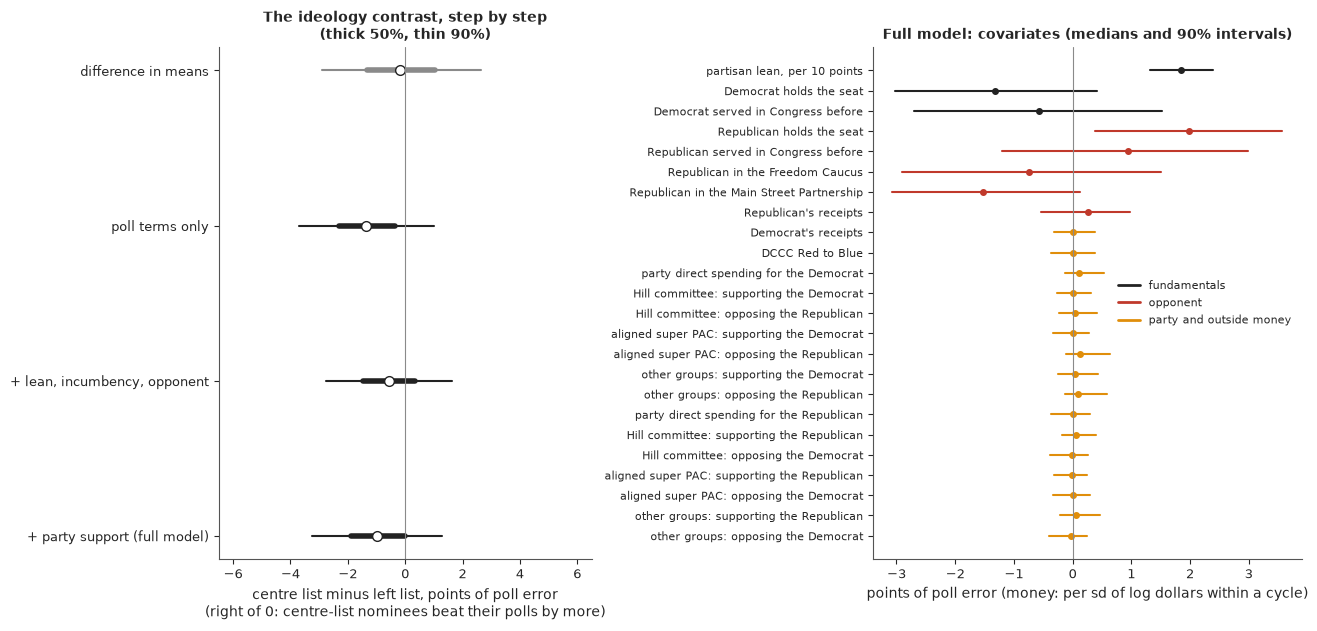

In [19]:
LABEL = {"lean": "partisan lean, per 10 points", "d_inc": "Democrat holds the seat", "d_served": "Democrat served in Congress before",
         "r_inc": "Republican holds the seat", "r_served": "Republican served in Congress before",
         "r_hfc": "Republican in the Freedom Caucus", "r_rmsp": "Republican in the Main Street Partnership",
         "r_receipts": "Republican's receipts", "d_receipts": "Democrat's receipts", "red_to_blue": "DCCC Red to Blue",
         "d_direct": "party direct spending for the Democrat", "r_direct": "party direct spending for the Republican"}
for s_, side in (("d", "Democrat"), ("r", "Republican")):
    for g_, grp in (("hill", "Hill committee"), ("aligned", "aligned super PAC"), ("other", "other groups")):
        other = "Republican" if s_ == "d" else "Democrat"
        LABEL[f"{s_}_{g_}_sup"] = f"{grp}: supporting the {side}"
        LABEL[f"{s_}_{g_}_opp"] = f"{grp}: opposing the {other}"

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), width_ratios=[1, 1.15])
ax = axes[0]
labs = ["difference in means"] + list(STEPS)
for i, lab in enumerate(labs):
    c = NAIVE_BS if i == 0 else STEPS[lab]["contrast"]
    med = NAIVE.loc["both cycles", "centre minus left"] if i == 0 else np.median(c)
    ax.plot(np.quantile(c, [0.05, 0.95]), [i, i], color=MUTED if i == 0 else INK, lw=1.5)
    ax.plot(np.quantile(c, [0.25, 0.75]), [i, i], color=MUTED if i == 0 else INK, lw=4)
    ax.plot(med, i, "o", color="white", mec=INK, ms=7)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(range(len(labs)), labs)
ax.invert_yaxis()
ax.set_xlim(-6.5, 6.5)
ax.set_xlabel("centre list minus left list, points of poll error\n(right of 0: centre-list nominees beat their polls by more)")
ax.set_title("The ideology contrast, step by step\n(thick 50%, thin 90%)", fontsize=10)
ax = axes[1]
names = list(FULL.posterior.x.values) + MONEY
for i, x in enumerate(names):
    r = COEF.loc[x]
    col = INK if x in PLAIN["fund"] else R_C if x in PLAIN["opp"] else CEN_C
    ax.plot([r["5%"], r["95%"]], [i, i], color=col, lw=1.5)
    ax.plot(r["median"], i, "o", color=col, ms=4)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(range(len(names)), [LABEL[x] for x in names], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("points of poll error (money: per sd of log dollars within a cycle)")
ax.legend(handles=[Line2D([], [], color=INK, lw=2, label="fundamentals"), Line2D([], [], color=R_C, lw=2, label="opponent"),
                   Line2D([], [], color=CEN_C, lw=2, label="party and outside money")], fontsize=8, loc="center right")
ax.set_title("Full model: covariates (medians and 90% intervals)", fontsize=10);

No step produces the gap the claim describes. The difference in means is -0.2. With the poll terms alone
(shared error, sponsor lean, noise by number of polls) the contrast is -1.35: left-list nominees' polls
were more often sponsored by their own side, so their raw poll error understated how they did against an
unsponsored average. Adding lean, incumbency and the opponent brings it back to about -0.6, because the
left bucket's districts are more Democratic and Democrats beat their polls in such districts whoever they
are. With party support the contrast is about **-1.0, with a 90% interval from -3.3 to +1.3**. The
probability that centre-list nominees did better against their polls is about 0.25.

The interval says two things. The data cannot tell which bucket did better: zero is well inside. And the
data do speak against a large advantage for the centre. The probability that centre-list nominees beat
their polls by 2 points or more than left-list nominees is under 2%, against about 22% for the reverse. A
gap of 3 points in favour of the centre is all but excluded for these two cycles.

The other terms are more informative than the lists. The **shared polling error** was small in both years,
+0.5 points in 2018 (-0.5 to +1.7) and -0.3 in 2022 (-1.6 to +1.1), under a prior that allowed 5. In both
years Democrats did better against House polls than against Senate polls, by about 1 and 2 points, though
each interval reaches zero. **Sponsored polls** lean 5 points (3.2 to 6.8) towards their sponsor.
**Partisan lean** is the strongest systematic term: for every 10 points of lean towards the Democrats, the
Democrat beats the polls by a further 1.85 points (1.3 to 2.4), so polls understate the stronger party in
lopsided places. **The opponent** matters through incumbency: against a Republican who holds the seat the
Democrat beats the polls by 2.0 points (0.4 to 3.6), and a Democrat who holds the seat falls short by 1.3
(-3.0 to +0.4). Polls flatter a Republican who holds the seat, an old observation among pollsters about
incumbents (Panagakis 1989). The estimate for a Democrat who holds the seat points the same way, but its
interval includes zero. The opponent's own lists point nowhere firm: -1.5 for the Main Street Partnership
and -0.7 for the Freedom Caucus, both with intervals that include zero.

**Party support** carries nothing. The common scale of the sixteen party-support coefficients is 0.19
(0.03 to 0.43), and no coefficient is distinguishable from zero. The parties did treat the buckets
differently, as the table above shows, but where the money went says almost nothing about who beat their
polls once lean and incumbency are known. That fits what money is known to do: it moves votes a little
(E94), and pollsters measure the votes it has moved.

## 6 · The bucket problem, part one: every reasonable definition

A bucket is a choice, and so far we have made each choice once. A commentator, or an analyst, could defend
many others, and a result that holds only under one of them is a result about the choice. A **multiverse
analysis** (Steegen, Tuerlinckx, Gelman and Vanpaemel 2016; the specification curve of Simonsohn, Simmons
and Nelson 2020) fits them all and shows the spread. Every definition here still uses only measures dated
before the election, with one marked exception.

The definitions are: any dated list (the main one); caucus rosters only; endorsement lists only; only the
lists that exist in all three cycles; and a centre made of the Blue Dog lists alone. Each is fitted on all
races, on nominees who do not hold the seat, and on House races. The main definition is also fitted on
each cycle alone, with windows of 42 and 70 days, and on unsponsored polls only. DW-NOMINATE enters as a
continuous measure, scaled so that one unit is the distance between the mean scores of the two buckets:
once with the scores captured before the 2022 election, and once, drawn hollow, with today's scores for
the members of both cycles, which were not fixed in advance. Four variants of the model complete the set:
normal errors, poll terms only, no party support, and the opponent's DW-NOMINATE added.

Twenty-odd refits of one model need one compilation. The likelihood is written as a `pm.Potential` with a
0/1 weight per race, so that buckets, rows and outcome are all `pm.Data`, and nutpie's `with_data` swaps
them.

In [20]:
SUP = ALL[ALL.cycle.isin([2018, 2022])].reset_index(drop=True)     # every race with a poll in the last 70 days
DS = design(SUP, ref=DM)
t0 = time.time()
MV = nutpie.compile_pymc_model(build_model(DS, likelihood="t", masked=True))
TIMES["compile the masked model"] = time.time() - t0


def refit(left, centre, rows, key="21"):
    """Refit the full model with other buckets, rows or poll window, without recompiling."""
    ok = rows & SUP[f"y_{key}"].notna().to_numpy()
    c = MV.with_data(L=np.asarray(left, float), C=np.asarray(centre, float), w=ok.astype(float),
                     y_obs=np.where(ok, SUP[f"y_{key}"], 0.0), n_polls=np.where(ok, SUP[f"n_{key}"], 1.0),
                     sponsor=np.where(ok, SUP[f"s_{key}"], 0.0))
    return nutpie.sample(c, chains=4, draws=1000, seed=RANDOM_SEED, progress_bar=False, target_accept=0.95)


ALL_ROWS = np.ones(len(SUP), bool)
DEFS = {"any dated list": (LEFT, CENTRE),
        "caucus rosters only": ([f for f in LEFT if f in ROSTERS], [f for f in CENTRE if f in ROSTERS]),
        "endorsement lists only": ([f for f in LEFT if f not in ROSTERS], [f for f in CENTRE if f not in ROSTERS]),
        "lists that exist in every cycle": (["cpc", "jd"], ["ndc", "blue_dog", "blue_dog_pac"]),
        "centre = Blue Dog lists only": (LEFT, ["blue_dog", "blue_dog_site", "blue_dog_pac"])}
SAMPLES = {"all races": ALL_ROWS, "not seat incumbents": (SUP.d_inc == 0).to_numpy(), "House only": (SUP.office == "H").to_numpy()}
arms = []
for dn, (lf, cf) in DEFS.items():
    for sn, rows in SAMPLES.items():
        arms.append({"definition": dn, "sample": sn, "outcome": "21 days", "L": any_flag(SUP, lf), "C": any_flag(SUP, cf),
                     "rows": rows, "key": "21", "dated": True})
for sn, rows in (("2018 only", (SUP.cycle == 2018).to_numpy()), ("2022 only", (SUP.cycle == 2022).to_numpy())):
    arms.append({"definition": "any dated list", "sample": sn, "outcome": "21 days", "L": SUP.left.to_numpy(), "C": SUP.centre.to_numpy(),
                 "rows": rows, "key": "21", "dated": True})
for on, key in (("42 days", "42"), ("70 days", "70"), ("21 days, unsponsored polls", "np")):
    arms.append({"definition": "any dated list", "sample": "all races", "outcome": on, "L": SUP.left.to_numpy(), "C": SUP.centre.to_numpy(),
                 "rows": ALL_ROWS, "key": key, "dated": True})
# DW-NOMINATE as a continuous measure: one unit = the gap between the mean scores of the two buckets
both_scores = SUP.dx_nominate_dim1_posthoc.notna()
GAP = float(SUP.dx_nominate_dim1_posthoc[both_scores & SUP.centre & ~SUP.left].mean()
            - SUP.dx_nominate_dim1_posthoc[both_scores & SUP.left & ~SUP.centre].mean())
for dn, col, dated in (("DW-NOMINATE dated before (2022 members)", "dx_nominate_dim1", True),
                       ("DW-NOMINATE from today's file (2018 and 2022 members)", "dx_nominate_dim1_posthoc", False)):
    has = SUP[col].notna().to_numpy()
    g_ = np.where(has, (SUP[col] - SUP[col][has].mean()) / GAP, 0.0)
    arms.append({"definition": dn, "sample": "members with a score", "outcome": "21 days", "L": -g_, "C": g_, "rows": has,
                 "key": "21", "dated": dated, "score": True})

t0 = time.time()
rows, MV_DRAWS = [], {}
for a in arms:
    ok = a["rows"] & SUP[f"y_{a['key']}"].notna().to_numpy()
    y_ = SUP[f"y_{a['key']}"].to_numpy()
    if a.get("score"):
        nl = nc_ = 99                                  # not buckets: every scored member enters
        naive = float(np.polyfit(a["C"][ok], y_[ok], 1)[0])
    else:
        lb, cb = a["L"].astype(bool) & ok, a["C"].astype(bool) & ok
        nl, nc_ = int((lb & ~cb).sum()), int((cb & ~lb).sum())
        naive = naive_contrast(y_[ok], a["L"].astype(bool)[ok], a["C"].astype(bool)[ok])
    label = f"{a['definition']} | {a['sample']} | {a['outcome']}"
    if min(nl, nc_) < 3:
        rows.append({"specification": label, "races": int(ok.sum()), "left": nl, "centre": nc_, "fitted": False})
        continue
    tr = refit(a["L"], a["C"], a["rows"], a["key"])
    c = tr.posterior["contrast"].values.ravel()
    MV_DRAWS[label] = c
    dg = diagnostics(tr)
    rows.append({"specification": label, "races": int(ok.sum()), "left": "-" if a.get("score") else nl,
                 "centre": "-" if a.get("score") else nc_, "fitted": True, "dated": a["dated"],
                 "no model": round(naive, 2), **contrast_row(c), "divergences": dg["divergences"],
                 "max r_hat": dg["max r_hat"], "min ESS": dg["min ESS"], "contrast ESS": ess_of(c)})
TIMES["multiverse refits"] = time.time() - t0
MVT = pd.DataFrame(rows)
print(MVT[~MVT.fitted][["specification", "races", "left", "centre"]].to_string(index=False))
MVT = MVT[MVT.fitted].drop(columns="fitted").reset_index(drop=True)
print(MVT.drop(columns=["dated"]).to_string(index=False))

                                      specification  races left centre
caucus rosters only | not seat incumbents | 21 days    126    1      3
                                                                         specification  races left centre  no model  centre minus left  90% lower  90% upper  P(centre > left)  divergences  max r_hat  min ESS  contrast ESS
                                                  any dated list | all races | 21 days    184   22     38     -0.18              -0.87       -3.3        1.4              0.26          0.0      1.006   1312.0        4153.0
                                        any dated list | not seat incumbents | 21 days    126   13     25     -2.15              -2.10       -5.1        0.8              0.12          0.0      1.005   1421.0        3906.0
                                                 any dated list | House only | 21 days    131   19     36      0.82               0.73       -1.8        3.2              0.68          0.0     

In [21]:
t0 = time.time()
extra = pd.DataFrame({"r_scored": MAIN.rx_nominate_dim1_posthoc.notna().astype(float)})
sc_ = MAIN.rx_nominate_dim1.where(MAIN.cycle == 2022, MAIN.rx_nominate_dim1_posthoc)   # no dated 2018 capture exists
extra["r_score"] = np.where(sc_.notna(), sc_ - sc_.mean(), 0.0)
f_x, dg_x = fit(DM, likelihood="t", extra=extra)
MODEL_ARMS = {"any dated list | all races | normal errors": (NORMAL_CONTRAST, diag_normal, True),
              "any dated list | all races | poll terms only": (STEPS["poll terms only"]["contrast"], STEPS["poll terms only"], True),
              "any dated list | all races | no party support": (STEPS["+ lean, incumbency, opponent"]["contrast"], STEPS["+ lean, incumbency, opponent"], True),
              "any dated list | all races | + opponent's DW-NOMINATE": (f_x.posterior["contrast"].values.ravel(), dg_x, False)}
print(az.summary(f_x, var_names=["beta_extra"], round_to=2).to_string())
del f_x
TIMES["opponent score model"] = time.time() - t0
base = MVT.iloc[0]
more = [{"specification": k, "races": len(MAIN), "left": base.left, "centre": base.centre, "dated": dated,
         "no model": base["no model"], **contrast_row(c), "divergences": dg["divergences"],
         "max r_hat": dg["max r_hat"], "min ESS": dg["min ESS"],
         "contrast ESS": ess_of(c)} for k, (c, dg, dated) in MODEL_ARMS.items()]
MV_DRAWS.update({k: v[0] for k, v in MODEL_ARMS.items()})
MVT = pd.concat([MVT, pd.DataFrame(more)], ignore_index=True)
print(pd.DataFrame(more).drop(columns=["dated"]).to_string(index=False))
med = MVT["centre minus left"]
print(f"{len(MVT)} specifications: medians from {med.min():+.1f} to {med.max():+.1f}, median of medians {med.median():+.1f}; "
      f"{int((med > 0).sum())} above zero, {int((med < 0).sum())} below")
print(f"90% intervals that exclude zero: {int(((MVT['90% lower'] > 0) | (MVT['90% upper'] < 0)).sum())} of {len(MVT)}")
print(f"P(centre > left) ranges from {MVT['P(centre > left)'].min():.2f} to {MVT['P(centre > left)'].max():.2f}")
print(f"worst diagnostics over the refits: {int(MVT.divergences.max())} divergences, r_hat {MVT['max r_hat'].max():.3f}, "
      f"lowest ESS of any variable {int(MVT['min ESS'].min())}, lowest ESS of the contrast {int(MVT['contrast ESS'].min())}")

                      mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
beta_extra[r_scored]  1.28  1.33     -0.81      3.41   2613.04   2614.67    1.0       0.03     0.02
beta_extra[r_score]   0.02  1.72     -2.68      2.81   6111.91   3108.15    1.0       0.02     0.03
                                        specification  races  left  centre  no model  centre minus left  90% lower  90% upper  P(centre > left)  divergences  max r_hat  min ESS  contrast ESS
           any dated list | all races | normal errors    184    22      38     -0.18              -1.04       -3.4        1.3              0.22            0      1.005      945          4310
         any dated list | all races | poll terms only    184    22      38     -0.18              -1.35       -3.7        1.0              0.18            0      1.005      802          2995
        any dated list | all races | no party support    184    22      38     -0.18              -0.57       -2.7        1.6  

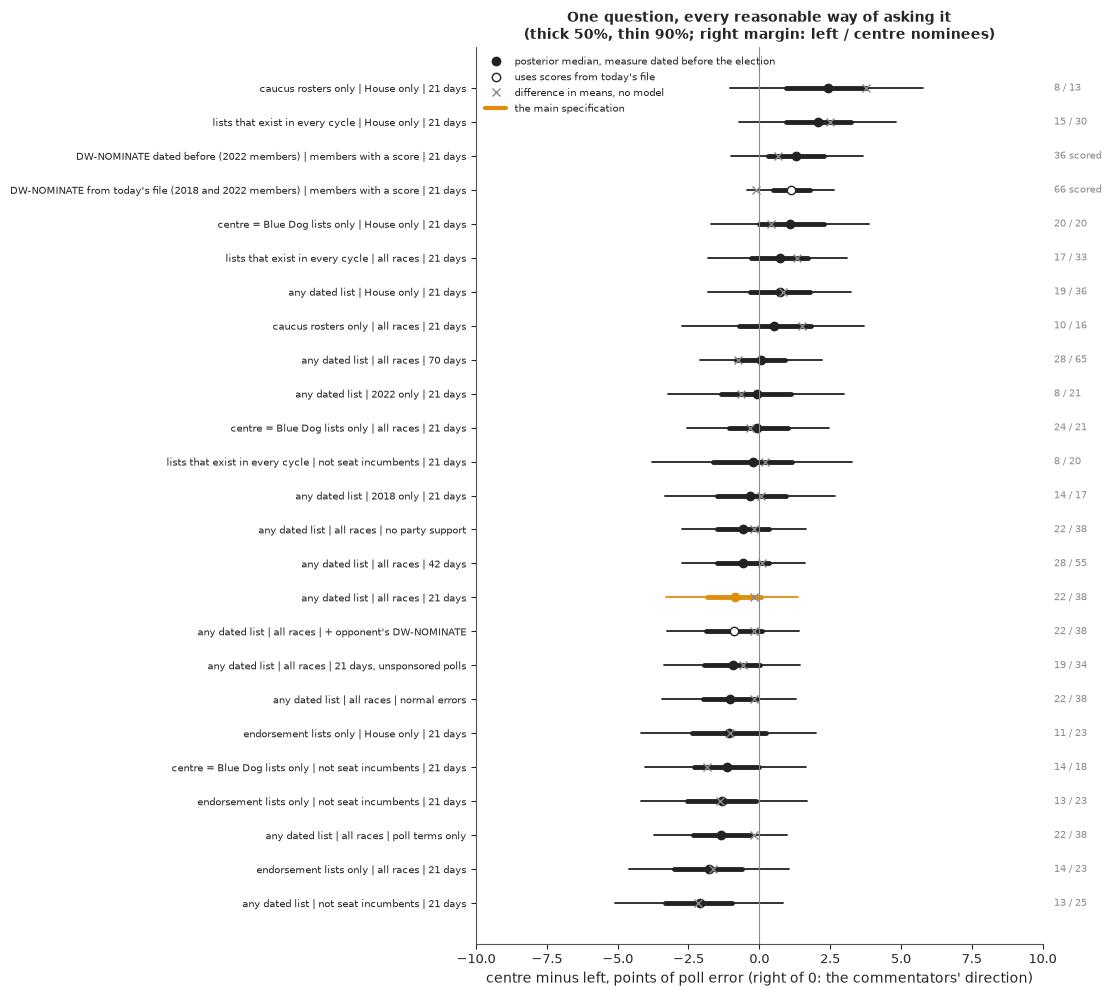

In [22]:
order = MVT.sort_values("centre minus left").index.to_list()
fig, ax = plt.subplots(figsize=(11, 0.33 * len(order) + 1.6))
for i, j in enumerate(order):
    r = MVT.loc[j]
    c = MV_DRAWS[r.specification]
    main_ = r.specification == "any dated list | all races | 21 days"
    col = CEN_C if main_ else INK
    ax.plot(np.quantile(c, [0.05, 0.95]), [i, i], color=col, lw=1.3)
    ax.plot(np.quantile(c, [0.25, 0.75]), [i, i], color=col, lw=3.5)
    ax.plot(np.median(c), i, "o", color=col if r.dated else "white", mec=col, ms=6)
    ax.plot(r["no model"], i, "x", color=MUTED, ms=6)
    ax.text(10.4, i, f"{r.races} scored" if r.left == "-" else f"{r.left} / {r.centre}", va="center", fontsize=7.5, color=MUTED)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_yticks(range(len(order)), [MVT.loc[j, "specification"] for j in order], fontsize=7.5)
ax.set_xlim(-10, 10)
ax.set_xlabel("centre minus left, points of poll error (right of 0: the commentators' direction)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=INK, label="posterior median, measure dated before the election"),
                   Line2D([], [], marker="o", ls="", color="white", mec=INK, label="uses scores from today's file"),
                   Line2D([], [], marker="x", ls="", color=MUTED, label="difference in means, no model"),
                   Line2D([], [], color=CEN_C, lw=3, label="the main specification")], fontsize=7.5, loc="upper left")
ax.set_title("One question, every reasonable way of asking it\n(thick 50%, thin 90%; right margin: left / centre nominees)", fontsize=10);

The 25 specifications give posterior medians from -2.1 to +2.4 points, 9 of them above zero and 16 below.
**No 90% interval excludes zero**, and the probability that the centre did better ranges from 0.12 to
0.89. (One combination was not fitted: among nominees who do not hold the seat, caucus rosters name one on
the left and three on the centre.)

The sign follows the choices in a readable way. Endorsement lists give a negative contrast in every
sample, and so does every definition among nominees who do not hold the seat, down to -2.1 (-5.1 to +0.8)
for any list among those nominees. Caucus rosters give a positive one, and so does the House-only sample
for every definition except endorsement lists, up to +2.4 (-1.0 to +5.8) for caucus rosters in House
races, which rests on 8 and 13 nominees. DW-NOMINATE gives about +1.2 either way. Wider poll windows add
50 to 80 races and change nothing (-0.6 at 42 days, +0.1 at 70). Unsponsored polls and the four model
variants stay between -1.4 and -0.5. Without any model (the crosses) the range is wider still, from -2.2
to +3.8.

So an analyst who is free to choose can report either sign with a straight face, and "caucus members in
House races" would be a reasonable-sounding choice that gives the commentators' direction. What no choice
gives is an interval that excludes zero. The refits sampled cleanly: no divergences, and an effective
sample size well over 1,000 for the contrast in every one. The weakest is the 2022-only refit, where the
whole model rests on 62 races and the worst $\hat R$ is about 1.02.

## 7 · The bucket problem, part two: labels given after the result

The multiverse held one thing fixed: every label was dated before the election. Commentary is not bound by
that. This section measures what happens when labels follow results, in three steps: evidence that even a
formal score moves after the fact, relabelling in the real data, and simulated elections in which ideology
does nothing.

### 7.1 A score is not a fixed fact

DW-NOMINATE is re-estimated as members cast more votes. The builder found a copy of Voteview's file
captured on 5 May 2022 and compared it with the file as it stands today.

2022 nominees scored in both the capture of 2022-05-05 and today's file: 403
  correlation 0.997, mean absolute shift 0.022, moved by more than 0.05: 48, largest shift 0.247
  distance between the bucket means among 2018 and 2022 Democratic members (the unit of section 6): 0.15
  Democrats: 202, of whom moved by more than 0.05: 31
2026 nominees, capture of 2026-10-08 against today's file: 387 scored, 0 moved by more than 0.05


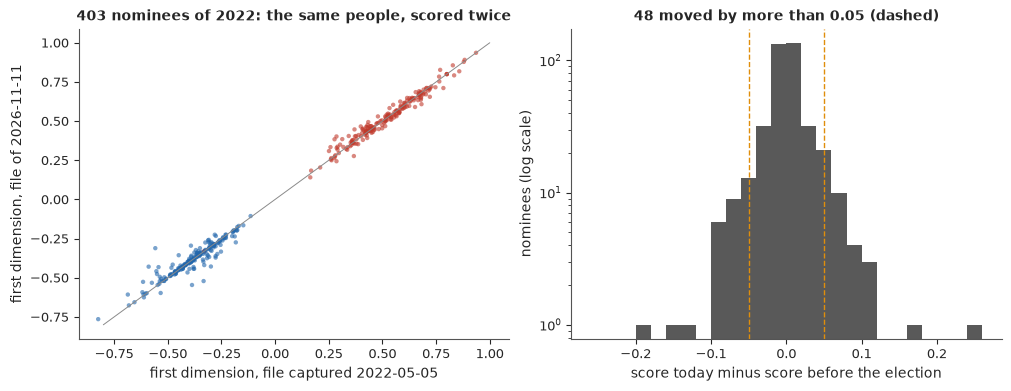

In [23]:
nv = ideo[(ideo.cycle == 2022) & ideo.nominate_dim1.notna() & ideo.nominate_dim1_posthoc.notna()]
shift = (nv.nominate_dim1_posthoc - nv.nominate_dim1).to_numpy()
print(f"2022 nominees scored in both the capture of {nv.nominate_snapshot_utc.iloc[0][:10]} and today's file: {len(nv)}")
print(f"  correlation {np.corrcoef(nv.nominate_dim1, nv.nominate_dim1_posthoc)[0, 1]:.3f}, mean absolute shift {np.abs(shift).mean():.3f}, "
      f"moved by more than 0.05: {int((np.abs(shift) > 0.05).sum())}, largest shift {np.abs(shift).max():.3f}")
dn = nv[nv.side == "D"]
print(f"  distance between the bucket means among 2018 and 2022 Democratic members (the unit of section 6): {GAP:.2f}")
print(f"  Democrats: {len(dn)}, of whom moved by more than 0.05: {int(((dn.nominate_dim1_posthoc - dn.nominate_dim1).abs() > 0.05).sum())}")
nv26 = ideo[(ideo.cycle == 2026) & ideo.nominate_dim1.notna() & ideo.nominate_dim1_posthoc.notna()]
print(f"2026 nominees, capture of {nv26.nominate_snapshot_utc.iloc[0][:10]} against today's file: {len(nv26)} scored, "
      f"{int(((nv26.nominate_dim1_posthoc - nv26.nominate_dim1).abs() > 0.05).sum())} moved by more than 0.05")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
ax.scatter(nv.nominate_dim1, nv.nominate_dim1_posthoc, s=10, color=np.where(nv.side == "D", D_C, R_C), alpha=0.6, edgecolor="none")
ax.plot([-0.8, 1], [-0.8, 1], color=MUTED, lw=0.7)
ax.set_xlabel("first dimension, file captured 2022-05-05")
ax.set_ylabel("first dimension, file of 2026-11-11")
ax.set_title(f"{len(nv)} nominees of 2022: the same people, scored twice", fontsize=10)
ax = axes[1]
ax.hist(shift, bins=np.arange(-0.26, 0.27, 0.02), color=INK, alpha=0.75)
for v in (-0.05, 0.05):
    ax.axvline(v, color=CEN_C, lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("score today minus score before the election")
ax.set_ylabel("nominees (log scale)")
ax.set_title(f"{int((np.abs(shift) > 0.05).sum())} moved by more than 0.05 (dashed)", fontsize=10);

For the 403 nominees of 2022 scored in both files the correlation is 0.997, which sounds like no change.
But 48 of them moved by more than 0.05 and the largest shift is 0.247. For scale, the mean scores of the
centre and left buckets among Democratic members are 0.15 apart. About one nominee in eight moved by a
third of the distance between the buckets, and one moved by more than the whole distance. The 2026 capture
is a month old and nothing has moved yet.

Nothing here says the scores moved because of an election result. They moved because members kept voting.
The point is narrower: a score looked up after an election is not the score that existed before it, and a
threshold drawn on it can put the same person in different buckets depending on when one looks.

### 7.2 Relabelling after the count

Now the cruder mechanism. Of the 184 nominees, 124 are open to labelling: 122 are on no list and 2 are on
both. Suppose a share of them is given a bucket after the count, by the rule that makes the story: a
nominee who beat the polls is called a moderate, one who fell short is called a progressive. Nobody labels
this mechanically, but any tendency in this direction works the same way, only more slowly. The nominees
with dated labels keep them. We draw the relabelled nominees at random 1,000 times for each share and
recompute the difference in means, then send four of the relabelled data sets through the full model.

In [24]:
QS = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0])
AMBIG = ~(LM ^ CM)                                   # on no list, or on lists of both sides


def relabel(y, left, centre, pick):
    """Give the picked nominees a bucket after the result: beat the polls -> centre, fell short -> left."""
    L2, C2 = left.copy(), centre.copy()
    L2[pick], C2[pick] = y[pick] < 0, y[pick] >= 0
    return L2, C2


def relabel_curve(y, g, reps):
    out = np.empty((reps, len(QS)))
    for r in range(reps):
        order = g.permutation(np.flatnonzero(AMBIG))
        for j, q in enumerate(QS):
            pick = np.zeros(len(y), bool)
            pick[order[: int(round(q * len(order)))]] = True
            out[r, j] = naive_contrast(y, *relabel(y, LM, CM, pick))
    return out


g = np.random.default_rng(RANDOM_SEED)
REAL = relabel_curve(yM, g, 1000)
print(f"{int(AMBIG.sum())} of {len(MAIN)} nominees are open to labelling: {int((~LM & ~CM).sum())} on no list, {int((LM & CM).sum())} on both")
print(pd.DataFrame({"share relabelled": QS, "nominees relabelled": np.round(QS * AMBIG.sum()).astype(int),
                    "difference in means, median": np.median(REAL, 0).round(1), "5%": np.quantile(REAL, 0.05, 0).round(1),
                    "95%": np.quantile(REAL, 0.95, 0).round(1)}).to_string(index=False))

# the same relabelled buckets through the full model
t0 = time.time()
in_main = SUP.n_21.notna().to_numpy() & SUP.y_21.notna().to_numpy()
assert in_main.sum() == len(MAIN) and (SUP.race[in_main].to_numpy() == MAIN.race.to_numpy()).all()
order = g.permutation(np.flatnonzero(AMBIG))
rows, RELAB = [], {}
for q in (0.1, 0.25, 0.5, 1.0):
    pick = np.zeros(len(MAIN), bool)
    pick[order[: int(round(q * len(order)))]] = True
    L2, C2 = relabel(yM, LM, CM, pick)
    Ls, Cs = SUP.left.to_numpy().copy(), SUP.centre.to_numpy().copy()
    Ls[in_main], Cs[in_main] = L2, C2
    tr = refit(Ls, Cs, ALL_ROWS)
    RELAB[q] = tr.posterior["contrast"].values.ravel()
    rows.append({"share relabelled": q, "nominees relabelled": int(pick.sum()), "difference in means": round(naive_contrast(yM, L2, C2), 1),
                 **contrast_row(RELAB[q]), "max r_hat": diagnostics(tr)["max r_hat"]})
TIMES["relabelled refits"] = time.time() - t0
RELAB_TAB = pd.DataFrame(rows)
print(RELAB_TAB.to_string(index=False))

124 of 184 nominees are open to labelling: 122 on no list, 2 on both
 share relabelled  nominees relabelled  difference in means, median   5%  95%
             0.00                    0                         -0.2 -0.2 -0.2
             0.05                    6                          0.7  0.2  1.4
             0.10                   12                          1.4  0.8  2.2
             0.20                   25                          2.6  1.9  3.5
             0.30                   37                          3.5  2.7  4.3
             0.50                   62                          4.7  4.0  5.3
             0.75                   93                          5.6  5.1  6.0
             1.00                  124                          6.2  6.2  6.2


 share relabelled  nominees relabelled  difference in means  centre minus left  90% lower  90% upper  P(centre > left)  max r_hat
             0.10                   12                  1.6               0.38       -1.7        2.4              0.62      1.005
             0.25                   31                  3.0               1.76       -0.0        3.6              0.95      1.007
             0.50                   62                  4.6               3.32        1.7        4.9              1.00      1.005
             1.00                  124                  6.2               4.35        3.1        5.6              1.00      1.005


The dated labels give -0.2. Relabel 6 of the 124 open nominees and the difference in means is +0.7;
relabel 12 and it is +1.4 (0.8 to 2.2); with 25 it is +2.6, with half of them +4.7, and with all of them
+6.2. The model does not protect against this. On the same relabelled buckets its contrast is +0.4 at a
tenth relabelled, +1.8 at a quarter with a 90% interval that just reaches zero, and +3.3 (1.7 to 4.9) at a
half. No covariate can adjust away a label that was built from the outcome.

### 7.3 Elections in which ideology does nothing

How much of this is the labels and how much is the data? We repeat the exercise in 400 simulated pairs of
elections drawn from the full model with both list effects set to zero: the same races, covariates and
buckets, new poll errors, and no ideology effect by construction.

400 simulated pairs of elections with no ideology effect
 share relabelled  difference in means, median   5%  95%  share of worlds above +2 points
             0.00                          0.1 -2.1  2.7                             0.14
             0.05                          1.1 -1.1  3.4                             0.26
             0.10                          1.8 -0.2  4.0                             0.44
             0.20                          3.1  1.1  5.1                             0.83
             0.30                          3.9  2.1  5.7                             0.95
             0.50                          5.0  3.6  6.6                             1.00
             0.75                          5.9  4.6  7.4                             1.00
             1.00                          6.6  5.3  7.8                             1.00
dated labels, no effect: sd of the difference in means 1.5 points; a gap of 2 points or more in either direction in 20% of worlds


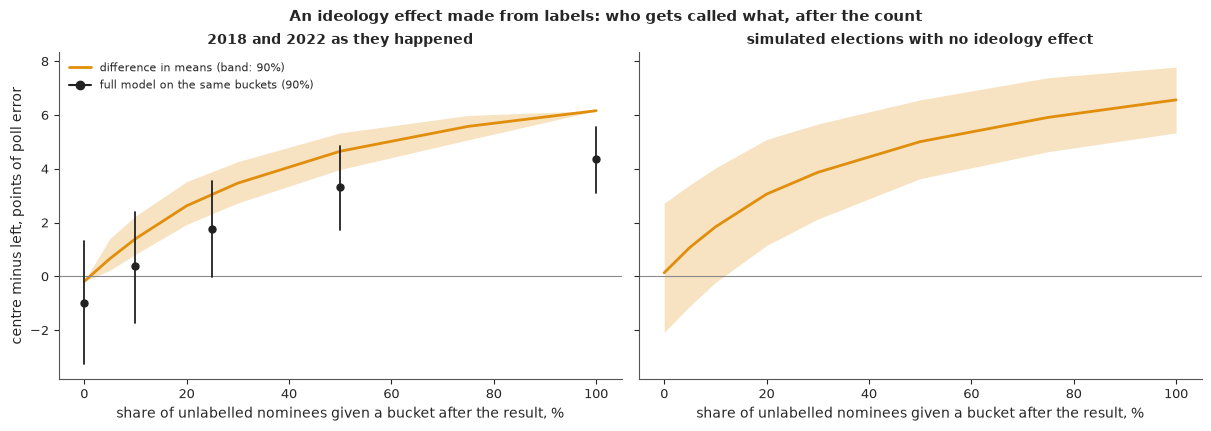

In [25]:
# worlds in which ideology has no effect at all: the full model's posterior with both list effects set to 0
NULL_Y = predict({k: v[:400] for k, v in DR.items()}, DM, zero_ideology=True, seed=RANDOM_SEED + 1)
g = np.random.default_rng(RANDOM_SEED + 2)
NULL = np.vstack([relabel_curve(y_, g, 1) for y_ in NULL_Y])
print(f"{len(NULL)} simulated pairs of elections with no ideology effect")
print(pd.DataFrame({"share relabelled": QS, "difference in means, median": np.median(NULL, 0).round(1),
                    "5%": np.quantile(NULL, 0.05, 0).round(1), "95%": np.quantile(NULL, 0.95, 0).round(1),
                    "share of worlds above +2 points": (NULL > 2).mean(0).round(2)}).to_string(index=False))
print(f"dated labels, no effect: sd of the difference in means {NULL[:, 0].std():.1f} points; "
      f"a gap of 2 points or more in either direction in {np.mean(np.abs(NULL[:, 0]) >= 2):.0%} of worlds")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (cur, lab) in zip(axes, ((REAL, "2018 and 2022 as they happened"), (NULL, "simulated elections with no ideology effect"))):
    ax.fill_between(QS * 100, np.quantile(cur, 0.05, 0), np.quantile(cur, 0.95, 0), color=CEN_C, alpha=0.25, lw=0)
    ax.plot(QS * 100, np.median(cur, 0), color=CEN_C, lw=2, label="difference in means (band: 90%)")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xlabel("share of unlabelled nominees given a bucket after the result, %")
    ax.set_title(lab, fontsize=10)
ax = axes[0]
c0 = STEPS["+ party support (full model)"]["contrast"]
for q, c in [(0.0, c0)] + list(RELAB.items()):
    ax.plot([q * 100] * 2, np.quantile(c, [0.05, 0.95]), color=INK, lw=1.3)
    ax.plot(q * 100, np.median(c), "o", color=INK, ms=5)
ax.plot([], [], "o-", color=INK, label="full model on the same buckets (90%)")
ax.set_ylabel("centre minus left, points of poll error")
ax.legend(fontsize=8, loc="upper left")
fig.suptitle("An ideology effect made from labels: who gets called what, after the count", fontsize=11);

The two panels look alike, which is the point: the real elections behave like elections with no ideology
effect. In the simulated ones, with dated labels, the difference in means is centred on zero with a
standard deviation of 1.5 points, so buckets of 22 and 38 produce a gap of 2 points or more, in one
direction or the other, in about one world in five. That is the noise a commentator can mine without
touching a label. With a tenth of the open nominees relabelled the median gap is +1.8 and it exceeds +2 in
44% of worlds; with a fifth relabelled it is +3.1 and exceeds +2 in about four worlds in five.

An apparent ideology effect of 2 to 3 points therefore needs no ideology. In these data it needs a dozen
or two of 184 candidates to be described after the count.

## 8 · 2026, provisional

The claim is heard again after the 2026 election, and 2026 cannot yet be analysed properly. On 11 November
nothing is certified. `e118_results_2026` holds vote counts read from Wikipedia's state and race articles
as they stood between 6 and 11 November: provisional counts for 30 of the 97 polled House races and 21 of
the 24 polled Senate races. The polled races of eleven states have no count at all. The source does not
say what share of the expected vote is in, late-counted ballots can move a margin by points, and the
missing states are not a random sample. Everything in this section compares provisional counts with a
model. None of it is a result.

The 2018 and 2022 model predicts a new cycle as follows. The shared error and its House-Senate split are
drawn from their priors, with the prior sd recomputed through 2022; state effects are drawn afresh; and
the buckets use the lists that can be dated for 2026. Red to Blue has no dated 2026 list, so that
covariate is held at its average and contributes nothing. The Hill committees filed no independent
expenditures in 2026 and report \$268M of coordinated spending instead, against \$22M and \$29M in the
two earlier cycles. Their independent-expenditure columns are therefore flat in 2026 and the
direct-spending column carries their choices; standardising within the cycle keeps the scale comparable.

provisional counts were read from Wikipedia revisions dated 2026-11-06 to 2026-11-11 and retrieved on 2026-11-11
polled races with a provisional count: {'H': '30 of 97', 'S': '21 of 24'}
states with polled races and no count for any of them (26 races): AZ, CT, ID, IL, MD, NV, NY, PA, RI, WA, WI
prior sd of the 2026 shared error, from 1998-2022: 3.3 points
2026 races with a final poll and an independent on the Democratic side (left out): 3, offices ['S']
Hill committees, $M: {2018: {'independent expenditures': 159, 'coordinated': 22}, 2022: {'independent expenditures': 256, 'coordinated': 29}, 2026: {'independent expenditures': 0, 'coordinated': 268}}
Democratic nominees of 2026 by dated list and by how recent the race's last poll is
bucket        left  centre  both  no list
last 21 days     1      34     1       25
last 42 days     3      43     1       37
last 70 days     6      50     1       44
count tables whose two-party share contradicts their printed percentages (left out): ['AL

full model refitted on 2018, 2022 and these 32 races of 2026: {'centre minus left': -0.89, '90% lower': -3.2, '90% upper': 1.3, 'P(centre > left)': 0.25} {'divergences': 0, 'max r_hat': 1.007, 'min ESS': 761}
  2026 shared polling error: +3.7 [+2.1, +5.5]


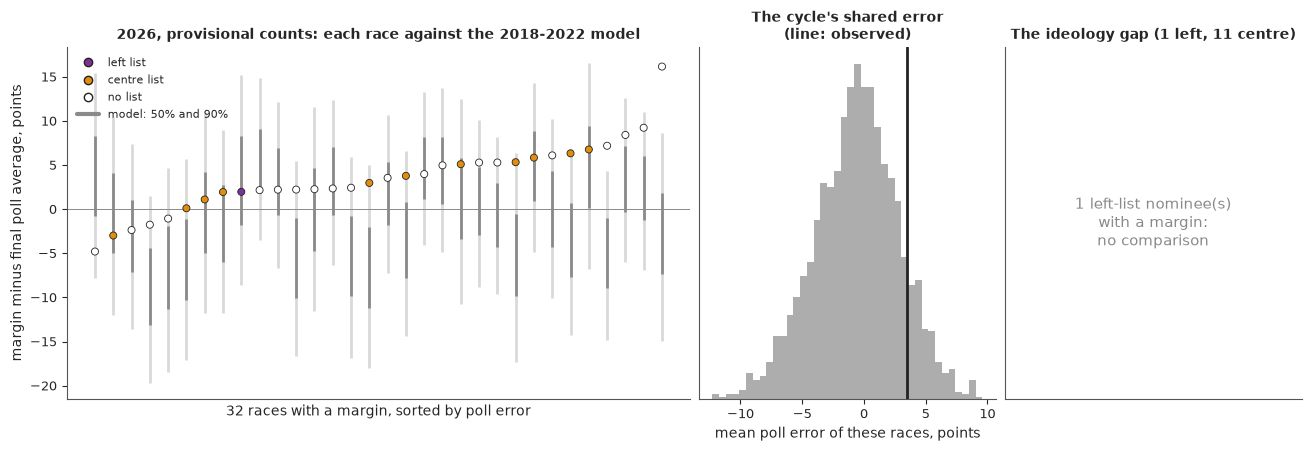

In [26]:
SD_B_NEW = float(np.sqrt(np.mean(np.r_[pollerr[pollerr.generic].groupby("cycle").err.mean().to_numpy(),
                                       pollerr[pollerr.type_simple == "Sen-G"].groupby("cycle").err.mean().to_numpy()] ** 2)))
A26 = ALL[(ALL.cycle == 2026) & ALL.n_21.notna()].reset_index(drop=True)
polled26 = ideo[(ideo.cycle == 2026) & (ideo.side == "D") & ideo.polled]
have = polled26.race.isin(counts26.race)
print("provisional counts were read from Wikipedia revisions dated", counts26.source_time_utc.min()[:10], "to",
      counts26.source_time_utc.max()[:10], "and retrieved on", counts26.retrieved_utc.max()[:10])
print("polled races with a provisional count:",
      {o: f"{int((have & (polled26.office == o)).sum())} of {int((polled26.office == o).sum())}" for o in ("H", "S")})
no_count = polled26[~have].groupby("state").size()
print(f"states with polled races and no count for any of them ({int((~polled26.state.isin(polled26.state[have])).sum())} races):",
      ", ".join(sorted(set(polled26.state[~have]) - set(polled26.state[have]))))
print(f"prior sd of the 2026 shared error, from 1998-2022: {SD_B_NEW:.1f} points")
ind26 = races[(races.cycle == 2026) & (races.d_is_ind == True) & races.race.isin(P.race[(P.cycle == 2026) & (P.days <= WINDOW)])]  # noqa: E712
print(f"2026 races with a final poll and an independent on the Democratic side (left out): {len(ind26)}, offices {sorted(set(ind26.office))}")
hill_ie = party_ie[(party_ie.version == "eve") & party_ie.nominee & (party_ie.group == "hill_committee")].groupby("cycle").amt.sum()
hill_co = party_direct[(party_direct.version == "pre_general") & (party_direct.group == "hill_committee")
                       & (party_direct.type == "coordinated")].groupby("cycle").amt.sum()
print("Hill committees, $M:", {int(c): {"independent expenditures": round(hill_ie.get(c, 0.0) / 1e6), "coordinated": round(hill_co.get(c, 0.0) / 1e6)}
                               for c in (2018, 2022, 2026)})
w26 = ALL[ALL.cycle == 2026]
print("Democratic nominees of 2026 by dated list and by how recent the race's last poll is")
print(pd.DataFrame({f"last {w} days": w26.bucket[w26[f"n_{w}"].notna()].value_counts() for w in (21, 42, 70)})
      .reindex(["left", "centre", "both", "no list"]).fillna(0).astype(int).T.to_string())


def section_2026(results, label, refit3=True):
    """Compare 2026 poll errors with what the 2018 and 2022 model expects. `results`: race and margin (two-party,
    D minus R, points). Run once on provisional counts and again, by the last cell, on certified results."""
    F = A26.merge(results[["race", "margin"]], on="race", how="left")
    F["y_21"] = F.margin - F.avg_21
    D26 = design(F, ref=DM)
    rep = predict(DR, D26, new_cycle=SD_B_NEW, seed=RANDOM_SEED + 26)
    k = F.margin.notna().to_numpy()
    y, L_, C_ = F.y_21.to_numpy()[k], F.left.to_numpy()[k], F.centre.to_numpy()[k]
    lo, hi = np.quantile(rep[:, k], [0.05, 0.95], 0)
    lo5, hi5 = np.quantile(rep[:, k], [0.25, 0.75], 0)
    mean_rep = rep[:, k].mean(1)
    con_rep = np.array([naive_contrast(r, L_, C_) for r in rep[:, k]])
    out = {"label": label, "F": F, "k": k, "rep": rep, "mean_rep": mean_rep, "con_rep": con_rep,
           "races": int(k.sum()), "of": len(F), "mean": float(y.mean()), "contrast": float(naive_contrast(y, L_, C_)),
           "n_left": int((L_ & ~C_).sum()), "n_centre": int((C_ & ~L_).sum())}
    if not k.any():
        print(f"--- 2026, {label}: no race of the {len(F)} has a margin ---")
        return out
    print(f"--- 2026, {label} ---")
    print(f"races with a poll in the last {WINDOW} days: {len(F)}; with a margin: {k.sum()} "
          f"({int((k & (F.office == 'H')).sum())} House, {int((k & (F.office == 'S')).sum())} Senate)")
    print("buckets among them:", pd.Series(F.bucket[k]).value_counts().to_dict())
    print(f"mean poll error: {y.mean():+.1f} points (sd {y.std():.1f}); the model expected {np.median(mean_rep):+.1f} "
          f"[{np.quantile(mean_rep, 0.05):+.1f}, {np.quantile(mean_rep, 0.95):+.1f}], P(as high or higher) = {np.mean(mean_rep >= y.mean()):.3f}")
    print(f"  by office: House {y[F.office[k] == 'H'].mean():+.1f}, Senate {y[F.office[k] == 'S'].mean():+.1f}")
    print(f"race intervals from the model: 90% covers {np.mean((y >= lo) & (y <= hi)):.0%}, 50% covers {np.mean((y >= lo5) & (y <= hi5)):.0%}")
    yc, repc = y - y.mean(), rep[:, k] - rep[:, k].mean(1, keepdims=True)
    loc, hic = np.quantile(repc, [0.05, 0.95], 0)
    print(f"  after removing the cycle's mean from both: 90% covers {np.mean((yc >= loc) & (yc <= hic)):.0%}; "
          f"sd {yc.std():.1f} against {np.median(repc.std(1)):.1f} [{np.quantile(repc.std(1), 0.05):.1f}, {np.quantile(repc.std(1), 0.95):.1f}]")
    bt_ = F[k].groupby("bucket").y_21.agg(races="size", mean="mean", sd="std").round(1)
    bt_.loc[bt_.races < MIN_BUCKET, ["mean", "sd"]] = np.nan
    print(bt_.to_string(na_rep="too few"))
    out["testable"] = min(out["n_left"], out["n_centre"]) >= MIN_BUCKET
    if out["testable"]:
        print(f"centre minus left, difference in means: {out['contrast']:+.1f} with {out['n_left']} left and {out['n_centre']} centre nominees; "
              f"the model expected {np.nanmedian(con_rep):+.1f} [{np.nanquantile(con_rep, 0.05):+.1f}, {np.nanquantile(con_rep, 0.95):+.1f}]")
    else:
        print(f"centre minus left: not computed, with {out['n_left']} left-list and {out['n_centre']} centre-list nominees "
              f"(at least {MIN_BUCKET} of each are needed)")
    if refit3:
        F3 = pd.concat([MAIN, F[k]], ignore_index=True)
        f3, dg3 = fit(design(F3), likelihood="t")
        out["contrast3"] = f3.posterior["contrast"].values.ravel()
        out["b26"] = f3.posterior["b"].sel(cycle=2026).values.ravel()
        print(f"full model refitted on 2018, 2022 and these {k.sum()} races of 2026:", contrast_row(out["contrast3"]),
              {q: dg3[q] for q in ("divergences", "max r_hat", "min ESS")})
        print(f"  2026 shared polling error: {np.median(out['b26']):+.1f} [{np.quantile(out['b26'], 0.05):+.1f}, {np.quantile(out['b26'], 0.95):+.1f}]")
    return out


def figure_2026(o):
    F, k, rep = o["F"], o["k"], o["rep"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), width_ratios=[2.1, 1, 1])
    ax = axes[0]
    idx = np.flatnonzero(k)
    idx = idx[np.argsort(F.y_21.to_numpy()[idx])]
    lo, hi = np.quantile(rep[:, idx], [0.05, 0.95], 0)
    lo5, hi5 = np.quantile(rep[:, idx], [0.25, 0.75], 0)
    x = np.arange(len(idx))
    ax.vlines(x, lo, hi, color=LIGHT, lw=2)
    ax.vlines(x, lo5, hi5, color=MUTED, lw=2)
    cols = F.bucket.map({"left": LEFT_C, "centre": CEN_C, "both": INK, "no list": "white"}).to_numpy()[idx]
    ax.scatter(x, F.y_21.to_numpy()[idx], s=26, c=list(cols), edgecolor=INK, linewidth=0.6, zorder=3,
               marker="o")
    ax.axhline(0, color=MUTED, lw=0.7)
    ax.set_xticks([])
    ax.set_xlabel(f"{len(idx)} races with a margin, sorted by poll error")
    ax.set_ylabel("margin minus final poll average, points")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", color=LEFT_C, mec=INK, label="left list"),
                       Line2D([], [], marker="o", ls="", color=CEN_C, mec=INK, label="centre list"),
                       Line2D([], [], marker="o", ls="", color="white", mec=INK, label="no list"),
                       Line2D([], [], color=MUTED, lw=3, label="model: 50% and 90%")], fontsize=8, loc="upper left")
    ax.set_title(f"2026, {o['label']}: each race against the 2018-2022 model", fontsize=10)
    ax = axes[1]
    ax.hist(o["mean_rep"], bins=40, color=MUTED, alpha=0.7, density=True)
    ax.axvline(o["mean"], color=INK, lw=2)
    ax.set_yticks([])
    ax.set_xlabel("mean poll error of these races, points")
    ax.set_title("The cycle's shared error\n(line: observed)", fontsize=10)
    ax = axes[2]
    if o["testable"]:
        ax.hist(o["con_rep"][np.isfinite(o["con_rep"])], bins=40, color=MUTED, alpha=0.7, density=True)
        ax.axvline(o["contrast"], color=INK, lw=2)
        ax.set_xlabel("centre minus left, difference in means")
    else:
        ax.text(0.5, 0.5, f"{o['n_left']} left-list nominee(s)\nwith a margin:\nno comparison", ha="center", va="center",
                fontsize=11, color=MUTED, transform=ax.transAxes)
        ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"The ideology gap ({o['n_left']} left, {o['n_centre']} centre)", fontsize=10)
    return fig


t0 = time.time()
prov = counts26[counts26.two_party_consistent != False].rename(columns={"margin2": "margin_two"})  # noqa: E712
prov = prov.assign(margin=prov.margin_two)[["race", "margin"]]
print("count tables whose two-party share contradicts their printed percentages (left out):",
      sorted(counts26.race[counts26.two_party_consistent == False]))  # noqa: E712
PROV = section_2026(prov, "provisional counts")
TIMES["2026 provisional"] = time.time() - t0
figure_2026(PROV);

Start with what cannot be done. Of the 61 races of 2026 with a poll in the last three weeks, 32 have a
provisional count, and among those 32 there is one left-list nominee, against 11 on a centre list and 20
on none. Certification will not repair this, because the 61 hold one left-list nominee in all (and one on
both kinds of list); even a 70-day window holds six. On dated lists and final polls, the 2026 comparison
of buckets has one nominee on one side. Anyone making it is using other labels or other polls.

What the provisional counts can show is whether 2026 looks like the two earlier cycles, and in one respect
it does not. In the 32 races the Democrats run **3.5 points ahead of their final polls** on average, 2.9
in the House races and 4.2 in the Senate races. The model, which had seen two quiet years, expected about
-0.5 with a 90% range from -6.4 to +4.9, and gives a shared error this large about one chance in nine.
That is the shared polling error doing what its history says it does. Refitted with these races as a third
cycle, the 2026 shared error is +3.7 points (2.1 to 5.5), several times anything the lists show, and it is
not confined to a bucket: centre-list nominees with a count are 3.3 points ahead of their polls and
no-list nominees 3.7. In a year like this, "moderates beat their polls" is true of the counts so far and
says nothing about moderates.

Race by race the model's 90% intervals cover 94% of the provisional errors and its 50% intervals 47%.
Around their own mean the 32 errors are less spread than the model expects, with a standard deviation of
4.0 against a predicted 5 to 8.5; nearly half of them are Senate races and the counts are incomplete, so
we read nothing into that yet. The ideology contrast in the three-cycle refit is -0.9 (-3.2 to +1.3),
unchanged, as it must be when 2026 adds a single left-list nominee.

In [27]:
extra_m = margins26[margins26.polled & margins26.margin.notna() & ~margins26.race.isin(prov.race)][["race", "margin"]]
cmp_ = margins26.merge(counts26[counts26.two_party_consistent != False][["race", "margin"]], on="race", suffixes=("_table", "_counts"))  # noqa: E712
print(f"the hidden table lists {len(margins26)} races within 10 points, {int(margins26.hidden_in_html_comment.sum())} of them inside an HTML comment; "
      f"it adds {len(extra_m)} polled races to the counts")
print(f"where both sources have a race ({len(cmp_)}), the margins differ by at most {(cmp_.margin_table - cmp_.margin_counts).abs().max():.1f} points")
SENS = section_2026(pd.concat([prov, extra_m], ignore_index=True), "provisional counts plus the hidden margins table", refit3=False)

the hidden table lists 121 races within 10 points, 121 of them inside an HTML comment; it adds 39 polled races to the counts
where both sources have a race (40), the margins differ by at most 0.2 points
--- 2026, provisional counts plus the hidden margins table ---
races with a poll in the last 21 days: 61; with a margin: 49 (34 House, 15 Senate)
buckets among them: {'centre': 24, 'no list': 23, 'both': 1, 'left': 1}
mean poll error: +2.8 points (sd 4.2); the model expected -1.5 [-7.3, +3.9], P(as high or higher) = 0.097
  by office: House +2.2, Senate +4.2
race intervals from the model: 90% covers 92%, 50% covers 45%
  after removing the cycle's mean from both: 90% covers 94%; sd 4.2 against 6.7 [5.3, 8.3]
         races    mean      sd
bucket                        
both         1 too few too few
centre      24     2.8     3.9
left         1 too few too few
no list     23     3.0     4.8
centre minus left: not computed, with 1 left-list and 24 centre-list nominees (at least 3 of each

One more source exists and is kept apart. `e118_results_2026_margins` is a table of the closest House
races that sat inside an HTML comment in the Wikipedia article, an editor's draft hidden from readers. It
gives margins without counts for 121 races within 10 points. Where it overlaps the counts (40 races) the
two agree within 0.2 points, and it adds 39 polled races, 17 of them among the 61. It is used only as this
check, for two reasons: it was never shown to readers, and it selects on the outcome, since a race is in
it only if it ended within 10 points, which removes the races most likely to have large errors. With it
the mean provisional error is +2.8 points over 49 races (+2.2 in the House), still about one chance in ten
under the model, and the buckets hold 24 centre-list nominees and still one left-list nominee.

## 9 · Scoring 2026, later

A provisional section should be rerun the same way whatever the certified results turn out to be. When
they exist, save them as `data/e94_results_2026.csv` with the columns `race` and `margin` (two-party,
Democratic minus Republican, in points): the file E94's scorer already waits for, so one file serves both
notebooks. The cell below then reruns section 8 on it: coverage, the cycle's shared error, the bucket
comparison if at least three nominees on each side have a margin, and the three-cycle refit. Until then it
says that the results are not available.

In [28]:
CERTIFIED_2026 = data.DATA_DIR / "e94_results_2026.csv"      # race, margin: the file E94's scorer waits for
if CERTIFIED_2026.exists():
    certified = pd.read_csv(CERTIFIED_2026)[["race", "margin"]]
    CERT = section_2026(certified, "certified results")
    figure_2026(CERT)
else:
    print("2026 certified results: not yet available. Section 8 stands on provisional counts until "
          f"{CERTIFIED_2026.name} exists.")
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

2026 certified results: not yet available. Section 8 stands on provisional counts until e94_results_2026.csv exists.
{'two parameterisations': 7, 'full model': 4, 'model steps': 6, 'compile the masked model': 3, 'multiverse refits': 21, 'opponent score model': 3, 'relabelled refits': 4, '2026 provisional': 4, 'total': 55}


## Summary

* **The claim is about poll error, and it was tested on labels fixed in advance.** The outcome is the
  certified margin minus the mean of the polls of the last 21 days, in 184 House and Senate races of 2018
  and 2022. Buckets come from rosters and endorsement lists dated before each election: 22 nominees on
  left lists, 38 on centre lists, none on the DSA list. The limit is the size of the left bucket.
* **Dated labels show no gap.** The difference in means is -0.2 points (-2.9 to +2.6). In the full model
  the centre-minus-left contrast is about -1.0 (-3.3 to +1.3): the data cannot tell which bucket did
  better, and they give under 2% to a centre advantage of 2 points or more.
* **The cycle, the district and the opponent matter more than the list.** Polls understate the stronger
  party by 1.85 points per 10 points of lean, flatter a Republican who holds the seat by 2 points, and
  lean 5 points towards a sponsor. The opponent measures are proxies for strength, not for likeability.
* **Party support differed by bucket and did not predict poll error.** Hill committees spent about twice
  as much on centre-list races, but the common scale of sixteen party-support coefficients is 0.19.
  Conditioning on money that follows close races compares nominees the parties treated alike, and no more.
* **Two failures on the way.** Three standard deviations that the data could not separate gave
  divergences and effective sample sizes in the low hundreds; a total and its shares gave none. Normal
  errors could not produce the largest misses; Student-t errors were adopted after that check.
* **The definition decides the sign, and nothing decides the interval.** Across 25 specifications the
  contrast runs from -2.1 to +2.4, and no 90% interval excludes zero.
* **Labels given after the result manufacture the effect.** Relabelling 12 of 124 open nominees by
  whether they beat their polls turns -0.2 into +1.4, and 25 make +2.6; the full model is fooled as well.
  In simulated elections with no ideology effect, dated labels still give a 2-point gap one time in five.
  Even DW-NOMINATE moved by more than 0.05 for 48 of 403 nominees between May 2022 and today.
* **2026 is provisional and cannot test the claim.** In 32 races with uncertified counts Democrats run 3.5
  points ahead of their final polls, centre-list and no-list nominees alike, a shared error the model
  gives about one chance in nine. Among the 61 races with a final poll there is one left-list nominee, so
  the comparison of buckets has nothing to compare, and the last cell reruns the section when certified
  results exist.

## Try it yourself

1. **Model the polls, not their average.** Give every poll of the last 70 days its own row: the result
   minus the race's error, plus the sponsor lean, a pollster effect and a drift term that grows with the
   poll's age. The race's error then becomes a latent quantity with the same covariates as here. Does
   the interval of the contrast narrow, and does the 70-day answer still agree with the 21-day one?
2. **The same question for Republicans.** `e118_ideology` dates the Freedom Caucus, the Republican Study
   Committee, the Main Street Partnership and the Republican Governance Group. Build the two buckets,
   flip the sign of the outcome, and rerun sections 3 to 7. Is the Republican contrast any better
   identified, and does the multiverse change sign in the same places?
3. **A subtler commentator, and a real effect.** Relabel only nominees whose poll error exceeds 5 points
   in absolute value, or relabel with a probability that rises with the size of the error. Then give the
   simulated elections a true effect of 1 point in favour of the left bucket. How much relabelling does
   it take to hide a real effect, and how much to reverse it?